# PHA Predictor — Entregable II

**Proyecto:** clasificación binaria de asteroides potencialmente peligrosos (PHA).
**Integrantes:** Eliana Maria Brand Agudelo, Jilberth Ferney Alzate Castaño, Juan Esteban Gil Quintero.
**Datos:** `neo.csv` (incluido en el repositorio, junto a este notebook; licencia CC0).

Este notebook reproduce las secciones III a VI del informe; las secciones I y II están en `entregable1.ipynb`.

1. **Entrenamiento y validación de modelos:** configuración experimental (3.1), resultados por fila (3.2), entrenamiento y validación por asteroide (3.3) y modelo definido: Random Forest (3.4).
2. **Reducción de dimensión** con los dos mejores modelos por asteroide: análisis individual de variables (4.1), PCA (4.2), UMAP (4.3) y representación del modelo definido (4.4).
3. **Evaluación final en prueba** del modelo definido (5). Es el único lugar donde se usa el conjunto de prueba.
4. **Discusión y conclusiones** (6).

*Tiempo de ejecución:* depende del número de núcleos (`N_JOBS = -1` usa todos).

In [1]:
import os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedGroupKFold, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             roc_curve, f1_score, precision_score, recall_score)
import umap

warnings.filterwarnings("ignore")
SEED, K_FOLDS, N_JOBS, SVM_MAX, B_BOOT = 42, 5, -1, 25000, 500
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "legend.fontsize": 6.5, "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})
candidates = [os.environ.get("NEO_CSV", ""), "neo.csv", "data/neo.csv"]
DATA_PATH = next((Path(p) for p in candidates if p and Path(p).exists()), None)
assert DATA_PATH is not None, "No se encontró neo.csv junto al notebook. Si falta, descárgalo desde el enlace de Kaggle."
t_start = time.time()
print("Datos:", DATA_PATH)

Datos: neo.csv


# 3. Entrenamiento y evaluación de modelos

## 3.1 Configuración experimental

### A. Metodología de validación

- **Variables de entrada (5):** $\log_{10}$ de `est_diameter_min` y `est_diameter_max`, `relative_velocity`, `miss_distance` y `absolute_magnitude` ($H$). Se eliminan `id`, `name` y las dos columnas constantes (ver Entregable I). Todo escalado (z-score) se ajusta **solo con el conjunto de entrenamiento** de cada pliegue, dentro del modelo.
- **Partición externa (prueba):** el 20 % de los *asteroides* (no de las filas) se reserva como conjunto de **prueba**. No se usa para ajustar ni para comparar: se evalúa una sola vez, al final (sección 5), con el modelo ya definido.
- **Validación interna:** con el 80 % restante se usa `StratifiedGroupKFold` con $K=5$ pliegues agrupados por `id`, estratificados por la clase. Se verifica con `assert` que ningún asteroide aparece a la vez en entrenamiento y validación (ni en desarrollo y prueba).
- **Selección de hiperparámetros:** malla completa; criterio = **PR-AUC** media en validación (no depende del umbral y es robusta al desbalance).
- **Umbral de decisión:** se elige el umbral que maximiza $F_1$ sobre las predicciones fuera de muestra (*out-of-fold*) del mejor modelo, y se aplica sin cambios a la prueba.
- **Desbalance:** pesos de clase (`class_weight`) como hiperparámetro en regresión logística y SVM, y umbral ajustado en todos. No se hace remuestreo salvo el del SVM.
- **Submuestreo del SVM:** el costo del SVM con núcleo RBF crece aproximadamente con $n^2$; por eso se entrena con una submuestra aleatoria de hasta 25 000 filas del conjunto de entrenamiento (la evaluación usa todas las filas de validación/prueba).

In [2]:
df = pd.read_csv(DATA_PATH)
FEATURES = ["log10 d_min", "log10 d_max", "velocidad", "dist. de paso", "H"]
X = np.column_stack([np.log10(df.est_diameter_min), np.log10(df.est_diameter_max),
                     df.relative_velocity, df.miss_distance, df.absolute_magnitude])
y = df.hazardous.astype(int).to_numpy()
groups = df.id.to_numpy()

# Partición externa: 20 % de los asteroides para prueba (estratificada y agrupada por id)
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(outer.split(X, y, groups))
Xd, yd, gd = X[dev_idx], y[dev_idx], groups[dev_idx]
Xt, yt, gt = X[test_idx], y[test_idx], groups[test_idx]
assert set(gd).isdisjoint(set(gt)), "un asteroide aparece en desarrollo y en prueba"

# Validación interna: K pliegues agrupados y estratificados
folds = list(StratifiedGroupKFold(K_FOLDS, shuffle=True, random_state=SEED).split(Xd, yd, gd))
for a, b in folds:
    assert set(gd[a]).isdisjoint(set(gd[b])), "un asteroide aparece en entrenamiento y validación"

rows = [("Desarrollo (entrenamiento + validación)", len(yd), len(set(gd)), yd.mean()),
        ("Prueba", len(yt), len(set(gt)), yt.mean())]
rows += [(f"  Pliegue {k+1}: entrenamiento / validación", f"{len(a)} / {len(b)}", f"{len(set(gd[a]))} / {len(set(gd[b]))}",
          f"{yd[a].mean():.3f} / {yd[b].mean():.3f}") for k, (a, b) in enumerate(folds)]
tab_split = pd.DataFrame(rows, columns=["Partición", "Filas", "Asteroides", "Fracción PHA"]); display(tab_split)
print("Verificación de agrupamiento: OK (sin asteroides compartidos entre particiones)")

,Partición,Filas,Asteroides,Fracción PHA
0,Desarrollo (entrenamiento + validación),72668,21938,0.097319
1,Prueba,18168,5485,0.097314
2,Pliegue 1: entrenamiento / validación,58134 / 14534,17550 / 4388,0.097 / 0.097
3,Pliegue 2: entrenamiento / validación,58134 / 14534,17550 / 4388,0.097 / 0.097
4,Pliegue 3: entrenamiento / validación,58135 / 14533,17551 / 4387,0.097 / 0.097
5,Pliegue 4: entrenamiento / validación,58135 / 14533,17550 / 4388,0.097 / 0.097
6,Pliegue 5: entrenamiento / validación,58134 / 14534,17551 / 4387,0.097 / 0.097


Verificación de agrupamiento: OK (sin asteroides compartidos entre particiones)


### Esquema de la partición

La figura resume el papel de cada conjunto. El **entrenamiento** ajusta los parámetros de cada configuración; la **validación** (los pliegues fuera de muestra) solo se usa para **seleccionar** hiperparámetros y umbral; la **prueba** se toca una sola vez, al final, con el **modelo ya definido** (hiperparámetros y umbral fijos, reentrenado con todo el desarrollo).

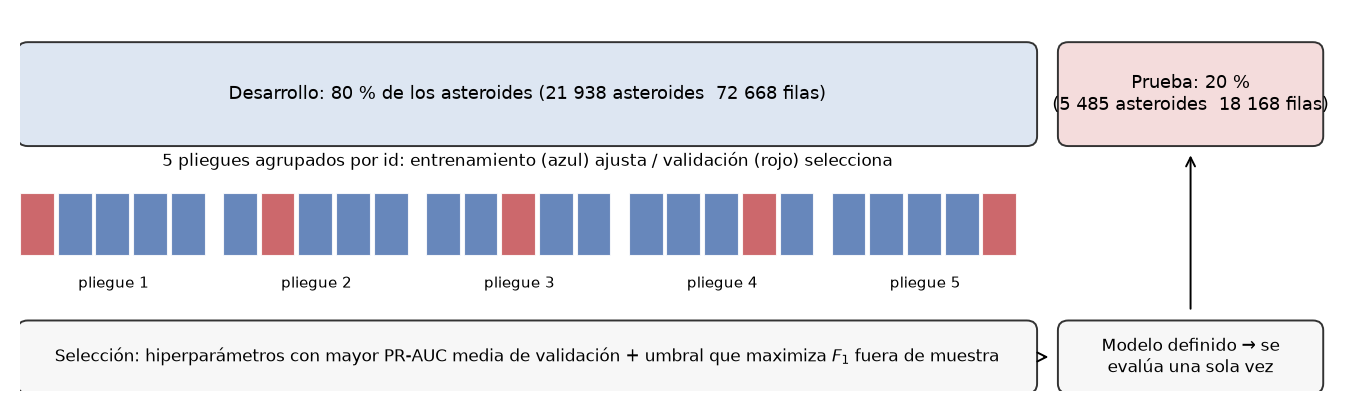

In [3]:
# Figura: esquema de la partición entrenamiento / validación / prueba (agrupada por asteroide)
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(7.0, 1.9)); ax.set_xlim(0, 101.5); ax.set_ylim(0, 30); ax.axis("off")
def caja(x, y, w, h, txt, fc, ec="#333333", fs=6.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.2,rounding_size=0.8", fc=fc, ec=ec, lw=0.7))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs)
n_ast = len(set(groups)); n_dev, n_te = len(set(gd)), len(set(gt))
caja(0, 20, 78, 8, f"Desarrollo: 80 % de los asteroides ({n_dev:,} asteroides, {len(yd):,} filas)".replace(",", " "), "#DDE6F2")
caja(80, 20, 20, 8, f"Prueba: 20 %\n({n_te:,} asteroides, {len(yt):,} filas)".replace(",", " "), "#F4DCDC")
for k in range(K_FOLDS):
    x0 = k * 15.6
    for j in range(K_FOLDS):
        ax.add_patch(FancyBboxPatch((x0 + j * 2.9, 11), 2.6, 5, boxstyle="square,pad=0", lw=0.4, ec="white",
                                    fc="#C44E52" if j == k else "#4C72B0", alpha=0.85))
    ax.text(x0 + 7.2, 9.3, f"pliegue {k+1}", ha="center", va="top", fontsize=5.5)
ax.text(39, 18.2, "5 pliegues agrupados por id: entrenamiento (azul) ajusta / validación (rojo) selecciona", ha="center", fontsize=6)
caja(0, 0, 78, 5.5, "Selección: hiperparámetros con mayor PR-AUC media de validación + umbral que maximiza $F_1$ fuera de muestra", "#F7F7F7", fs=6)
caja(80, 0, 20, 5.5, "Modelo definido → se\nevalúa una sola vez", "#F7F7F7", fs=6)
ax.annotate("", xy=(90, 6.2), xytext=(90, 19.5), arrowprops=dict(arrowstyle="<-", lw=0.7))
ax.annotate("", xy=(79.5, 2.75), xytext=(78.3, 2.75), arrowprops=dict(arrowstyle="->", lw=0.7))
fig.tight_layout(pad=0.2); fig_split = fig
plt.show()

### B. Modelos e hiperparámetros analizados

| Familia | Modelo | Hiperparámetros analizados |
|---|---|---|
| Paramétrico (regresión) | Regresión logística (L2) | $C$, `class_weight` |
| No paramétrico | $k$ vecinos más cercanos (KNN) | $k$, ponderación de vecinos |
| Ensamble de árboles | Random Forest (150 árboles) | profundidad máxima, mínimo de muestras por hoja |
| Red neuronal artificial | Perceptrón multicapa (ReLU, Adam, parada temprana) | capas ocultas, regularización $\alpha$ |
| Máquina de vectores de soporte | SVM con núcleo RBF | $C$, $\gamma$, `class_weight` |

In [4]:
GRIDS = {
    "Regresión logística": dict(C=[0.01, 0.1, 1, 10, 100], class_weight=["ninguno", "balanced"]),
    "KNN":                 dict(k=[5, 11, 25, 51, 101, 201], weights=["uniform", "distance"]),
    "Random Forest":       dict(max_depth=[4, 8, 12, 0], min_samples_leaf=[1, 10, 50]),     # 0 = sin límite
    "Red neuronal (MLP)":  dict(hidden=["16", "64", "64-32"], alpha=[1e-4, 1e-2, 1.0]),
    "SVM (RBF)":           dict(C=[1, 10], gamma=[0.05, 0.2, 1.0], class_weight=["ninguno", "balanced"]),
}
display(pd.DataFrame([(m, h, ", ".join(map(str, v))) for m, g in GRIDS.items() for h, v in g.items()],
                     columns=["Modelo", "Hiperparámetro", "Valores (malla)"]))
print("Configuraciones por modelo:", {m: len(ParameterGrid(g)) for m, g in GRIDS.items()})

,Modelo,Hiperparámetro,Valores (malla)
0,Regresión logística,C,"0.01, 0.1, 1, 10, 100"
1,Regresión logística,class_weight,"ninguno, balanced"
2,KNN,k,"5, 11, 25, 51, 101, 201"
3,KNN,weights,"uniform, distance"
4,Random Forest,max_depth,"4, 8, 12, 0"
5,Random Forest,min_samples_leaf,"1, 10, 50"
6,Red neuronal (MLP),hidden,"16, 64, 64-32"
7,Red neuronal (MLP),alpha,"0.0001, 0.01, 1.0"
8,SVM (RBF),C,"1, 10"
9,SVM (RBF),gamma,"0.05, 0.2, 1.0"


Configuraciones por modelo: {'Regresión logística': 10, 'KNN': 12, 'Random Forest': 12, 'Red neuronal (MLP)': 9, 'SVM (RBF)': 12}


### C. Métricas de desempeño y justificación

| Métrica | Definición | Por qué se usa |
|---|---|---|
| **PR-AUC** (precisión promedio) | área bajo la curva precisión–recall | Criterio principal: sensible a la clase minoritaria; su valor de referencia al azar es la prevalencia (≈ 0.097). |
| **ROC-AUC** | $\Pr[s(\mathbf{x}^+)>s(\mathbf{x}^-)]$ | Complementaria y comparable con la literatura. Con 90 % de negativos fáciles puede resultar optimista. |
| **$F_1$ de la clase PHA** | $2PR/(P+R)$ | Resume el compromiso entre falsas alarmas y PHA no detectados al umbral elegido. |
| **Precisión** y **Recall** | $TP/(TP+FP)$ y $TP/(TP+FN)$ | Costos asimétricos: no detectar un PHA es más grave que una falsa alarma. |

La **exactitud** no se usa: un clasificador trivial que dice siempre "no peligroso" alcanza 90.27 %. Los intervalos de confianza de validación son $\bar{x}\pm t_{0.975,\,K-1}\,s/\sqrt{K}$ sobre los $K=5$ pliegues; los de prueba son intervalos percentil al 95 % de un *bootstrap por asteroide* (se remuestrean asteroides completos, no filas).

In [5]:
METRICS = ["ROC_AUC", "PR_AUC", "F1", "Precision", "Recall"]

def best_f1_threshold(y_true, s):
    p, r, t = precision_recall_curve(y_true, s)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return t[np.argmax(f1)]

def metrics(y_true, s, thr):
    pred = s >= thr
    return dict(ROC_AUC=roc_auc_score(y_true, s), PR_AUC=average_precision_score(y_true, s),
                F1=f1_score(y_true, pred, zero_division=0), Precision=precision_score(y_true, pred, zero_division=0),
                Recall=recall_score(y_true, pred, zero_division=0))

def ci95(v):
    v = np.asarray(v, float)
    return stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))

def make_model(name, p):
    if name == "Random Forest":
        mf = p.get("max_features", "sqrt")
        mf = int(mf) if isinstance(mf, (int, float, np.number)) else mf      # entero = número de variables por división
        return RandomForestClassifier(n_estimators=int(p.get("n_estimators", 150)),
                                      max_depth=None if p["max_depth"] == 0 else int(p["max_depth"]),
                                      min_samples_leaf=int(p["min_samples_leaf"]), max_features=mf,
                                      n_jobs=1, random_state=SEED)
    cw = None if p.get("class_weight", "ninguno") == "ninguno" else "balanced"
    if name == "Regresión logística":
        clf = LogisticRegression(C=p["C"], class_weight=cw, max_iter=2000)
    elif name == "KNN":
        clf = KNeighborsClassifier(n_neighbors=p["k"], weights=p["weights"])
    elif name == "Red neuronal (MLP)":
        clf = MLPClassifier(hidden_layer_sizes=tuple(int(h) for h in p["hidden"].split("-")), alpha=p["alpha"],
                            early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, max_iter=300, random_state=SEED)
    elif name == "SVM (RBF)":
        clf = SVC(C=p["C"], gamma=p["gamma"], class_weight=cw, kernel="rbf", cache_size=1000)
    return make_pipeline(StandardScaler(), clf)

def score(m, Xe):
    return m.predict_proba(Xe)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xe)

def fit_scores(name, p, Xtr, ytr, Xevs, seed=0):
    if name == "SVM (RBF)" and len(ytr) > SVM_MAX:                       # submuestreo solo para el ajuste del SVM
        idx = np.random.RandomState(seed).choice(len(ytr), SVM_MAX, replace=False)
        m = make_model(name, p).fit(Xtr[idx], ytr[idx])
    else:
        m = make_model(name, p).fit(Xtr, ytr)
    return [score(m, Xe) for Xe in Xevs]

def _task_grid(name, p, Xtr, ytr, Xva, yva, seed):
    s, = fit_scores(name, p, Xtr, ytr, [Xva], seed)
    return roc_auc_score(yva, s), average_precision_score(yva, s)

def grid_search(name, Xc):
    cfgs = list(ParameterGrid(GRIDS[name]))
    jobs = [(i, k) for i in range(len(cfgs)) for k in range(K_FOLDS)]
    out = Parallel(n_jobs=N_JOBS)(delayed(_task_grid)(name, cfgs[i], Xc[folds[k][0]], yd[folds[k][0]],
                                                      Xc[folds[k][1]], yd[folds[k][1]], k) for i, k in jobs)
    return pd.DataFrame([dict(model=name, **cfgs[i], fold=k, ROC_AUC=o[0], PR_AUC=o[1]) for (i, k), o in zip(jobs, out)])

def _fit_eval(name, p, Xtr, ytr, Xva, seed):
    return fit_scores(name, p, Xtr, ytr, [Xtr, Xva], seed)

def collect(res_folds):
    """Une las predicciones por pliegue: umbral global sobre las predicciones fuera de muestra (validación) y métricas
    de entrenamiento y validación. La prueba NO se usa aquí: se reserva para el modelo definido (sección 5)."""
    oof = np.zeros(len(yd))
    for k, (a, b) in enumerate(folds):
        oof[b] = res_folds[k][1]
    thr = best_f1_threshold(yd, oof)
    return dict(thr=thr, oof=oof,
                train=[metrics(yd[a], res_folds[k][0], thr) for k, (a, b) in enumerate(folds)],
                val=[metrics(yd[b], res_folds[k][1], thr) for k, (a, b) in enumerate(folds)])

def run_model(name, p, tr_list, va_list):
    res = Parallel(n_jobs=N_JOBS)(delayed(_fit_eval)(name, p, tr_list[k], yd[folds[k][0]], va_list[k], k) for k in range(K_FOLDS))
    return collect(res)

def run_raw(name, p, cols=None):
    cols = list(range(X.shape[1])) if cols is None else list(cols)
    Xc = Xd[:, cols]
    return run_model(name, p, [Xc[a] for a, b in folds], [Xc[b] for a, b in folds])

def fmt_val(vals, m):  return f"{np.mean([v[m] for v in vals]):.3f} ± {ci95([v[m] for v in vals]):.3f}"
def fmt_train(ev, m): return f"{np.mean([v[m] for v in ev['train']]):.3f}"

def results_table(R, labels, metrics_list=("PR_AUC", "ROC_AUC", "F1")):
    rows = []
    for lab in labels:
        ev = R[lab]
        row = {"Modelo": lab}
        for m in metrics_list:
            row[f"{m} entren."] = fmt_train(ev, m)
            row[f"{m} valid. (± IC95)"] = fmt_val(ev["val"], m)
        rows.append(row)
    return pd.DataFrame(rows)
print("Funciones auxiliares definidas")

Funciones auxiliares definidas


## 3.2 Resultados del entrenamiento de modelos

### Búsqueda de hiperparámetros (validación agrupada, 5 pliegues)

In [6]:
t0 = time.time()
res_grid = pd.concat([grid_search(m, Xd) for m in GRIDS], ignore_index=True)
print(f"Búsqueda completa: {len(res_grid)} ajustes en {(time.time()-t0)/60:.1f} min")

PCOLS = ["C", "class_weight", "k", "weights", "max_depth", "min_samples_leaf", "hidden", "alpha", "gamma"]
def agg_model(m):
    g = res_grid[res_grid.model == m]
    cols = [c for c in PCOLS if g[c].notna().any()]
    a = g.groupby(cols, dropna=False).agg(PR_AUC=("PR_AUC", "mean"), PR_sd=("PR_AUC", "std"),
                                           ROC_AUC=("ROC_AUC", "mean")).reset_index()
    return a.sort_values("PR_AUC", ascending=False), cols

best = {}
for m in GRIDS:
    a, cols = agg_model(m)
    best[m] = {c: a.iloc[0][c] for c in cols}
    for c, v in best[m].items():
        if c in ("k", "max_depth", "min_samples_leaf"): best[m][c] = int(v)       # enteros
        elif isinstance(v, (np.integer, np.floating)): best[m][c] = float(v)
    print(f"\n{m}: mejores 3 configuraciones (de {len(a)})")
    display(a.head(3).round(4))
print("\nMejores hiperparámetros:", best)

Búsqueda completa: 275 ajustes en 3.4 min

Regresión logística: mejores 3 configuraciones (de 10)


,C,class_weight,PR_AUC,PR_sd,ROC_AUC
9,100.0,ninguno,0.3017,0.0089,0.8731
7,10.0,ninguno,0.3017,0.0089,0.8731
5,1.0,ninguno,0.3017,0.0089,0.8731



KNN: mejores 3 configuraciones (de 12)


,k,weights,PR_AUC,PR_sd,ROC_AUC
10,201.0,distance,0.5100,0.0185,0.9108
8,101.0,distance,0.5078,0.0169,0.9100
6,51.0,distance,0.5034,0.0157,0.9087



Random Forest: mejores 3 configuraciones (de 12)


,max_depth,min_samples_leaf,PR_AUC,PR_sd,ROC_AUC
6,8.0,1.0,0.5027,0.0137,0.9096
8,8.0,50.0,0.5024,0.0129,0.9099
7,8.0,10.0,0.5018,0.0124,0.9094



Red neuronal (MLP): mejores 3 configuraciones (de 9)


,hidden,alpha,PR_AUC,PR_sd,ROC_AUC
6,64-32,0.0001,0.5029,0.0125,0.9103
7,64-32,0.0100,0.5020,0.0143,0.9102
4,64,0.0100,0.4994,0.0152,0.9100



SVM (RBF): mejores 3 configuraciones (de 12)


,C,class_weight,gamma,PR_AUC,PR_sd,ROC_AUC
10,10.0,ninguno,0.20,0.4653,0.0127,0.8879
4,1.0,ninguno,0.20,0.4571,0.0125,0.8841
9,10.0,ninguno,0.05,0.4568,0.0108,0.8916



Mejores hiperparámetros: {'Regresión logística': {'C': 100.0, 'class_weight': 'ninguno'}, 'KNN': {'k': 201, 'weights': 'distance'}, 'Random Forest': {'max_depth': 8, 'min_samples_leaf': 1}, 'Red neuronal (MLP)': {'hidden': '64-32', 'alpha': 0.0001}, 'SVM (RBF)': {'C': 10.0, 'class_weight': 'ninguno', 'gamma': 0.2}}


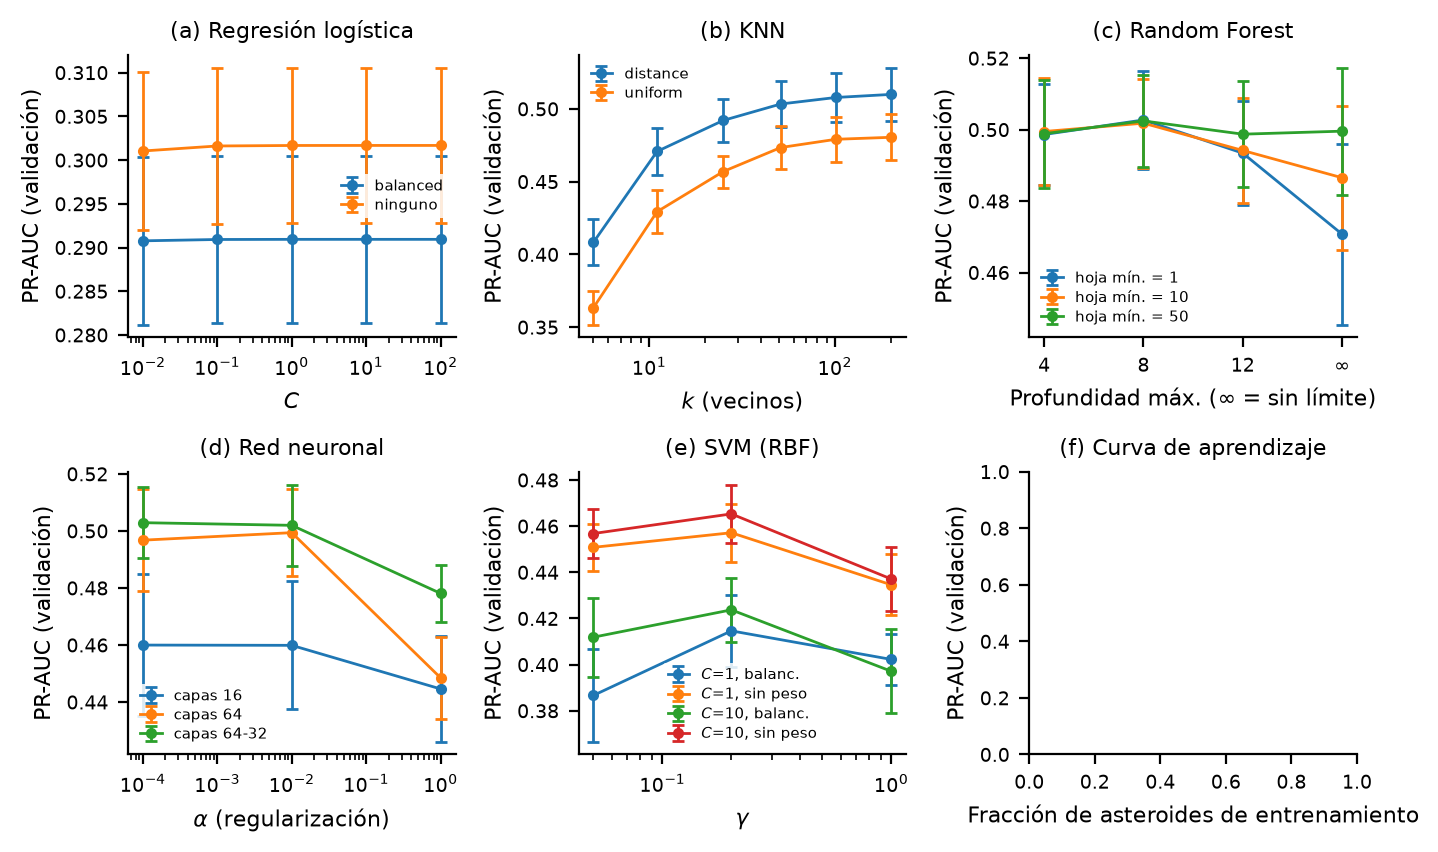

In [7]:
# Figura: efecto de los hiperparámetros (validación) y curva de aprendizaje
LEG = dict(frameon=True, framealpha=0.85, edgecolor="none", fontsize=5.5, handlelength=1.4, borderpad=0.3, labelspacing=0.25)
def lines(ax, m, x, hue, xlabel, logx=False, xticklabels=None, hue_fmt=None):
    a, cols = agg_model(m)
    order = (lambda v: 1e9 if v == 0 else v) if xticklabels else (lambda v: v)      # 0 = "sin límite" va al final
    for h, g in a.groupby(hue):
        g = g.groupby(x).agg(PR_AUC=("PR_AUC", "mean"), PR_sd=("PR_sd", "mean")).reset_index()
        g = g.assign(_o=g[x].map(order)).sort_values("_o")
        lab = hue_fmt(h) if hue_fmt else str(h)
        ax.errorbar(range(len(g)) if xticklabels else g[x], g.PR_AUC, yerr=g.PR_sd, marker="o", ms=3, lw=1, capsize=2, label=lab)
    if xticklabels:
        xs = sorted(a[x].unique(), key=order); ax.set_xticks(range(len(xs))); ax.set_xticklabels([xticklabels(v) for v in xs])
    if logx: ax.set_xscale("log")
    ax.set_xlabel(xlabel); ax.set_ylabel("PR-AUC (validación)")
    ax.legend(loc="best", **LEG)

fig, ax = plt.subplots(2, 3, figsize=(7.0, 4.3))
lines(ax[0, 0], "Regresión logística", "C", "class_weight", "$C$", logx=True); ax[0, 0].set_title("(a) Regresión logística")
lines(ax[0, 1], "KNN", "k", "weights", "$k$ (vecinos)", logx=True); ax[0, 1].set_title("(b) KNN")
lines(ax[0, 2], "Random Forest", "max_depth", "min_samples_leaf", "Profundidad máx. (∞ = sin límite)",
      xticklabels=lambda v: "∞" if v == 0 else str(int(v)), hue_fmt=lambda h: f"hoja mín. = {int(h)}"); ax[0, 2].set_title("(c) Random Forest")
lines(ax[1, 0], "Red neuronal (MLP)", "alpha", "hidden", "$\\alpha$ (regularización)", logx=True, hue_fmt=lambda h: f"capas {h}"); ax[1, 0].set_title("(d) Red neuronal")
a_svm, _ = agg_model("SVM (RBF)")
for (C_, cw), g in a_svm.groupby(["C", "class_weight"]):
    g = g.sort_values("gamma"); ax[1, 1].errorbar(g.gamma, g.PR_AUC, yerr=g.PR_sd, marker="o", ms=3, lw=1, capsize=2,
                                                  label=f"$C$={C_:g}, {'balanc.' if cw == 'balanced' else 'sin peso'}")
ax[1, 1].set_xscale("log"); ax[1, 1].set_xlabel("$\\gamma$"); ax[1, 1].set_ylabel("PR-AUC (validación)")
ax[1, 1].legend(loc="best", **LEG); ax[1, 1].set_title("(e) SVM (RBF)")
ax_lc = ax[1, 2]; ax_lc.set_title("(f) Curva de aprendizaje"); ax_lc.set_xlabel("Fracción de asteroides de entrenamiento"); ax_lc.set_ylabel("PR-AUC (validación)")
fig.tight_layout(); fig_hyper = fig
plt.show()

### Mejor configuración de cada modelo: entrenamiento y validación

Se reajusta cada mejor configuración en los 5 pliegues y se fija el umbral con las predicciones fuera de muestra. Todo se mide en **entrenamiento y validación**: la prueba no se usa para comparar modelos, sino solo una vez, con el modelo ya definido (sección 5). Se añaden dos referencias: un **clasificador constante** (todo PHA) y una **regresión logística que usa solo $H$**.

In [8]:
t0 = time.time()
R = {}
for m in GRIDS:
    R[m] = run_raw(m, best[m])
    print(f"{m}: umbral F1 = {R[m]['thr']:.3f}  ({time.time()-t0:.0f} s)")
R["Solo H (reg. logística)"] = run_raw("Regresión logística", dict(C=1, class_weight="ninguno"), cols=[4])
# Referencia constante: puntuación igual para todos y umbral que marca todo como PHA
R["Constante (todo PHA)"] = dict(thr=0.0, oof=np.zeros(len(yd)),
                                 val=[metrics(yd[b], np.zeros(len(b)), 0.0) for a, b in folds],
                                 train=[metrics(yd[a], np.zeros(len(a)), 0.0) for a, b in folds])
MODELS = list(GRIDS)
BASES = ["Solo H (reg. logística)", "Constante (todo PHA)"]
tab_main = results_table(R, MODELS + BASES)
print(f"Evaluación completa en {(time.time()-t0)/60:.1f} min")
display(tab_main.set_index("Modelo").T)

Regresión logística: umbral F1 = 0.121  (0 s)


KNN: umbral F1 = 0.199  (8 s)


Random Forest: umbral F1 = 0.267  (16 s)


Red neuronal (MLP): umbral F1 = 0.199  (25 s)


SVM (RBF): umbral F1 = -1.002  (60 s)


Evaluación completa en 1.0 min


Modelo,Regresión logística,KNN,Random Forest,Red neuronal (MLP),SVM (RBF),Solo H (reg. logística),Constante (todo PHA)
PR_AUC entren.,0.300,1.000,0.591,0.514,0.472,0.272,0.097
PR_AUC valid. (± IC95),0.302 ± 0.011,0.510 ± 0.023,0.503 ± 0.017,0.503 ± 0.015,0.465 ± 0.016,0.275 ± 0.010,0.097 ± 0.000
ROC_AUC entren.,0.873,1.000,0.932,0.914,0.890,0.863,0.500
ROC_AUC valid. (± IC95),0.873 ± 0.005,0.911 ± 0.007,0.910 ± 0.008,0.910 ± 0.006,0.888 ± 0.005,0.863 ± 0.006,0.500 ± 0.000
F1 entren.,0.448,1.000,0.521,0.484,0.445,0.460,0.177
F1 valid. (± IC95),0.448 ± 0.008,0.481 ± 0.014,0.485 ± 0.015,0.481 ± 0.016,0.442 ± 0.008,0.461 ± 0.015,0.177 ± 0.000


In [9]:
# Resumen por modelo con precisión, recall y exactitud de referencia (validación)
rows = []
for lab in MODELS + BASES:
    ev = R[lab]
    pred = ev["oof"] >= ev["thr"]
    rows.append({"Modelo": lab, "Umbral": round(float(ev["thr"]), 3), "Precisión valid.": fmt_val(ev["val"], "Precision"),
                 "Recall valid.": fmt_val(ev["val"], "Recall"), "Exactitud valid. (ref.)": round(float((pred == yd).mean()), 4)})
tab_pr = pd.DataFrame(rows); display(tab_pr)
BEST_MODEL = max(MODELS, key=lambda m: np.mean([v["PR_AUC"] for v in R[m]["val"]]))
print("Mejor modelo por PR-AUC de validación (por fila):", BEST_MODEL)

,Modelo,Umbral,Precisión valid.,Recall valid.,Exactitud valid. (ref.)
0,Regresión logística,0.121,0.309 ± 0.009,0.818 ± 0.024,0.8037
1,KNN,0.199,0.328 ± 0.013,0.903 ± 0.010,0.8104
2,Random Forest,0.267,0.354 ± 0.013,0.767 ± 0.018,0.8412
3,Red neuronal (MLP),0.199,0.327 ± 0.018,0.910 ± 0.039,0.8083
4,SVM (RBF),-1.002,0.341 ± 0.012,0.630 ± 0.021,0.8454
5,Solo H (reg. logística),0.098,0.301 ± 0.013,0.984 ± 0.016,0.7758
6,Constante (todo PHA),0.000,0.097 ± 0.000,1.000 ± 0.000,0.0973


Mejor modelo por PR-AUC de validación (por fila): KNN


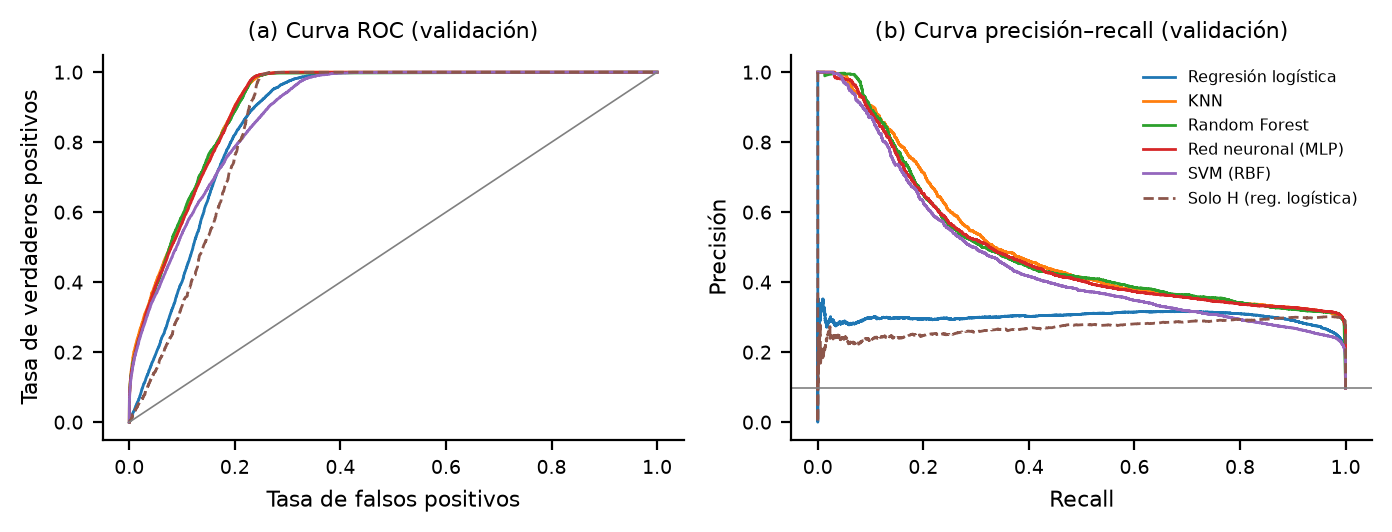

In [10]:
# Figura: curvas ROC y PR con las predicciones fuera de muestra (validación) del desarrollo
fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.7))
for lab in MODELS + ["Solo H (reg. logística)"]:
    s = R[lab]["oof"]
    fpr, tpr, _ = roc_curve(yd, s); ax[0].plot(fpr, tpr, lw=1, ls="--" if lab.startswith("Solo") else "-", label=lab)
    p_, r_, _ = precision_recall_curve(yd, s); ax[1].plot(r_, p_, lw=1, ls="--" if lab.startswith("Solo") else "-", label=lab)
ax[0].plot([0, 1], [0, 1], color="gray", lw=.6); ax[1].axhline(yd.mean(), color="gray", lw=.6)
ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos"); ax[0].set_title("(a) Curva ROC (validación)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precisión"); ax[1].set_title("(b) Curva precisión–recall (validación)")
ax[1].legend(frameon=False, loc="upper right", fontsize=5.8)
fig.tight_layout(); fig_curves = fig
plt.show()

### Curva de aprendizaje y techo de desempeño

La etiqueta oficial depende del MOID, que no está en la base. Para estimar el **techo práctico** se hacen tres comprobaciones: (i) si las cinco familias de modelos convergen a un mismo valor; (ii) si la curva de aprendizaje del mejor modelo se estanca al aumentar los datos; y (iii) cómo se comporta el mejor modelo dentro del subconjunto $H\le22$, único lugar donde la clase es realmente incierta (fuera de él casi todo es negativo). Las tres se miden con el conjunto de desarrollo (predicciones fuera de muestra).

,frac,mean,std
0,0.10,0.4392,0.0244
1,0.25,0.4720,0.0130
2,0.50,0.4915,0.0186
3,0.75,0.4999,0.0194
4,1.00,0.5100,0.0185


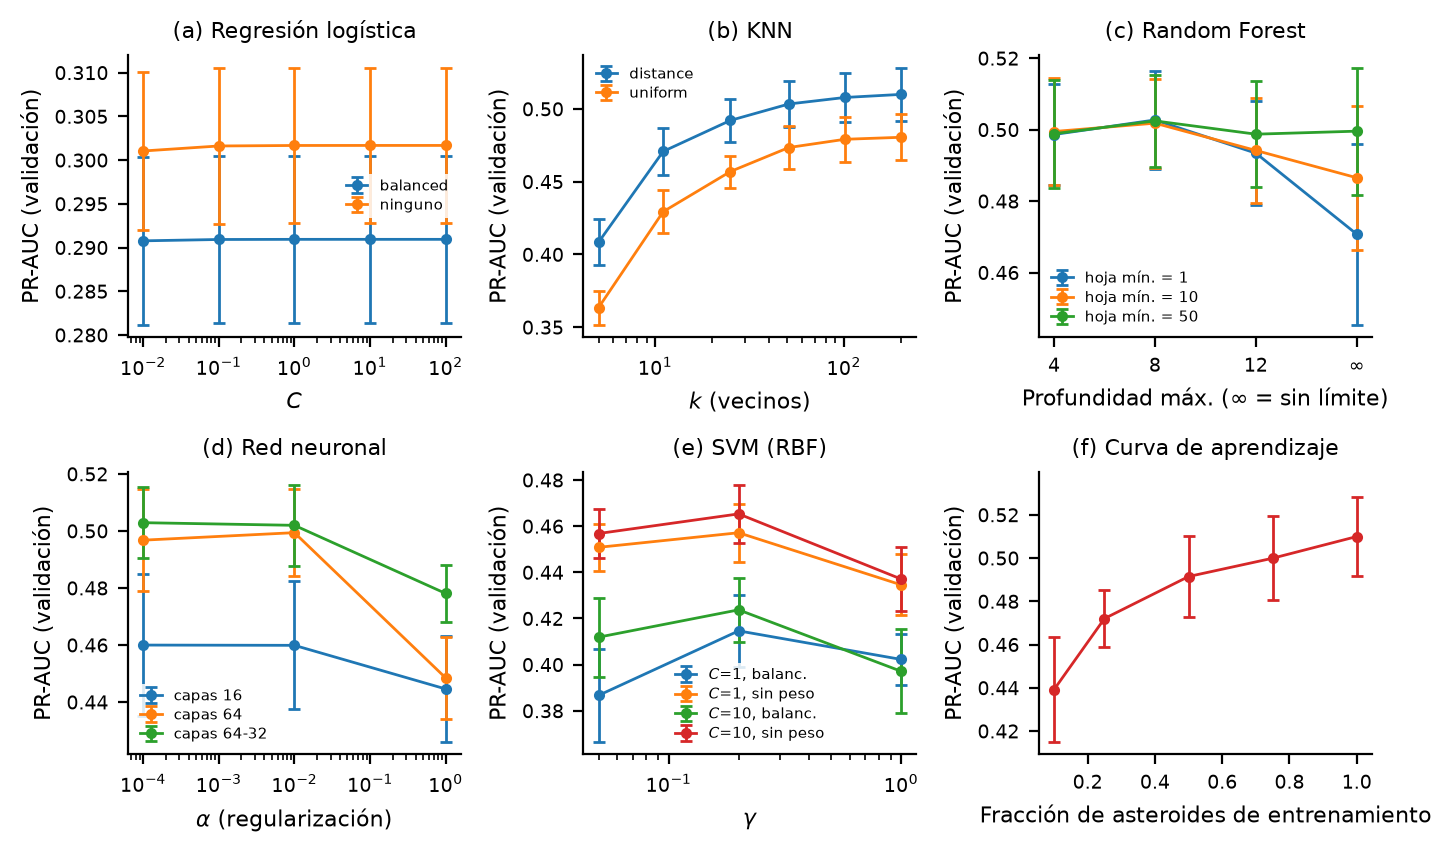

Filas de desarrollo con H <= 22: 23372 (32.2%); fracción PHA dentro: 0.300
KNN dentro de H<=22:  ROC-AUC = 0.654   PR-AUC = 0.512
Solo H dentro de H<=22:        ROC-AUC = 0.457   PR-AUC = 0.272
Positivos de desarrollo con H > 22 (no detectables por la regla H<=22): 72 de 7072
PR-AUC de validación por familia: {'Regresión logística': np.float64(0.302), 'KNN': np.float64(0.51), 'Random Forest': np.float64(0.503), 'Red neuronal (MLP)': np.float64(0.503), 'SVM (RBF)': np.float64(0.465)}


In [11]:
def _task_lc(name, p, k, frac):
    a, b = folds[k]
    rng = np.random.RandomState(k)
    ug = np.unique(gd[a]); keep = rng.choice(ug, max(2, int(frac * len(ug))), replace=False)
    sel = a[np.isin(gd[a], keep)]
    s, = fit_scores(name, p, Xd[sel], yd[sel], [Xd[b]], k)
    return average_precision_score(yd[b], s)

fracs = [0.1, 0.25, 0.5, 0.75, 1.0]
jobs = [(f, k) for f in fracs for k in range(K_FOLDS)]
out = Parallel(n_jobs=N_JOBS)(delayed(_task_lc)(BEST_MODEL, best[BEST_MODEL], k, f) for f, k in jobs)
lc = pd.DataFrame([dict(frac=f, fold=k, PR_AUC=o) for (f, k), o in zip(jobs, out)]).groupby("frac").PR_AUC.agg(["mean", "std"]).reset_index()
display(lc.round(4))
ax_lc.errorbar(lc.frac, lc["mean"], yerr=lc["std"], marker="o", ms=3, lw=1, capsize=2, color="C3")
ax_lc.set_ylim(lc["mean"].min() - 0.03, lc["mean"].max() + 0.03)
fig_hyper.tight_layout(); display(fig_hyper)

# Dentro de H <= 22 (donde la clase es incierta), con las predicciones fuera de muestra del mejor modelo
mask = Xd[:, 4] <= 22
s_b = R[BEST_MODEL]["oof"]
print(f"Filas de desarrollo con H <= 22: {mask.sum()} ({mask.mean():.1%}); fracción PHA dentro: {yd[mask].mean():.3f}")
print(f"{BEST_MODEL} dentro de H<=22:  ROC-AUC = {roc_auc_score(yd[mask], s_b[mask]):.3f}   PR-AUC = {average_precision_score(yd[mask], s_b[mask]):.3f}")
print(f"Solo H dentro de H<=22:        ROC-AUC = {roc_auc_score(yd[mask], -Xd[mask, 4]):.3f}   PR-AUC = {average_precision_score(yd[mask], -Xd[mask, 4]):.3f}")
print(f"Positivos de desarrollo con H > 22 (no detectables por la regla H<=22): {int(((yd==1)&(~mask)).sum())} de {int(yd.sum())}")
best_vals = {m: np.mean([v['PR_AUC'] for v in R[m]['val']]) for m in MODELS}
print("PR-AUC de validación por familia:", {m: round(v, 3) for m, v in best_vals.items()})

### Unidad de la velocidad: validación y sensibilidad

Kaggle no declara la unidad de `relative_velocity`. En `entregable1.ipynb` (sección 1.B.3) se valida contra aproximaciones publicadas por la NASA/JPL: la columna está en **km/h** y `miss_distance` en **km** (por ejemplo, 2001 FO32 aparece con 123 887 km/h y la NASA reporta unos 124 000 km/h). Además, como todo modelo sensible a la escala recibe la variable estandarizada, un cambio de unidad es un reescalado lineal y no debería alterar los resultados; se verifica en un pliegue.

In [12]:
a, b = folds[0]
unit_tests = {"km/h (supuesta)": 1.0, "km/s": 1 / 3600, "mph": 0.621371}
rows = []
for name in ["Regresión logística", "KNN", "Red neuronal (MLP)", "SVM (RBF)"]:
    row = {"Modelo": name}
    for u, f in unit_tests.items():
        Xs_ = Xd.copy(); Xs_[:, 2] = Xs_[:, 2] * f
        s, = fit_scores(name, best[name], Xs_[a], yd[a], [Xs_[b]], 0)
        row[u] = round(average_precision_score(yd[b], s), 4)
    rows.append(row)
tab_unit = pd.DataFrame(rows); display(tab_unit)

,Modelo,km/h (supuesta),km/s,mph
0,Regresión logística,0.2974,0.2974,0.2974
1,KNN,0.4914,0.4914,0.4914
2,Red neuronal (MLP),0.4920,0.4920,0.4920
3,SVM (RBF),0.4438,0.4438,0.4438


## 3.3 Un asteroide, varias aproximaciones: entrenamiento y evaluación por asteroide

Cada fila es una aproximación, pero la etiqueta (y $H$) es del **asteroide**: el mismo objeto aparece de 1 a 43 veces, y los PHA aparecen en promedio más veces (4.1 filas) que los no PHA (3.2). Las métricas por fila de la sección 3.2 cuentan entonces más de una vez a los asteroides con muchas aproximaciones, y en el entrenamiento esos asteroides también pesan más. Para que la unidad de análisis sea el asteroide se hacen dos cambios:

1. **Peso por id en el ajuste:** cada fila recibe $w_i = 1/n_{\text{id}(i)}$ (normalizado a media 1), de modo que todos los asteroides aportan lo mismo a la función de pérdida, tengan una o cuarenta aproximaciones. Se pasa como `sample_weight` a regresión logística, Random Forest, red neuronal y SVM; como `KNeighborsClassifier` no admite pesos, se implementa un KNN equivalente en el que el voto de cada vecino se multiplica por su peso.
2. **Una predicción por asteroide:** la probabilidad de un asteroide es el **promedio de las probabilidades** de sus filas, y todas las métricas (PR-AUC, ROC-AUC, $F_1$, precisión, recall y **exactitud**) se calculan sobre asteroides.

La búsqueda de hiperparámetros se repite con este esquema (misma malla, mismos pliegues, criterio: PR-AUC por asteroide en validación); el umbral maximiza $F_1$ sobre las predicciones fuera de muestra **promediadas por asteroide**, y la prueba no se usa: se reserva para el modelo definido (sección 5). Para separar el efecto de los pesos del efecto de evaluar por asteroide se comparan dos estrategias, ambas evaluadas por asteroide:

- **Sin pesos:** los modelos de la sección 3.2 (hiperparámetros elegidos por fila), solo cambiando la evaluación.
- **Con pesos por id:** pesos $1/n$ y hiperparámetros elegidos por asteroide.

In [13]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score

class KNNPonderado(BaseEstimator, ClassifierMixin):
    # KNN con sample_weight: el voto de cada vecino se multiplica por su peso (KNeighborsClassifier no lo admite).
    def __init__(self, n_neighbors=5, weights="uniform"):
        self.n_neighbors, self.weights = n_neighbors, weights
    def fit(self, X, y, sample_weight=None):
        self.nn_ = NearestNeighbors(n_neighbors=self.n_neighbors).fit(X)
        self.y_ = np.asarray(y, float)
        self.w_ = np.ones(len(self.y_)) if sample_weight is None else np.asarray(sample_weight, float)
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        d, idx = self.nn_.kneighbors(X)
        if self.weights == "distance":
            with np.errstate(divide="ignore"):
                v = 1.0 / d
            cero = (d == 0).any(axis=1)                      # como scikit-learn: si hay vecinos a distancia 0, solo votan ellos
            v[cero] = (d[cero] == 0).astype(float)
        else:
            v = np.ones_like(d)
        v = v * self.w_[idx]
        p1 = (v * self.y_[idx]).sum(axis=1) / v.sum(axis=1)
        return np.column_stack([1 - p1, p1])

def pesos_por_id(g):
    # w = 1 / (número de filas del asteroide), normalizado a media 1: cada asteroide pesa lo mismo en el ajuste.
    _, inv, cnt = np.unique(g, return_inverse=True, return_counts=True)
    w = 1.0 / cnt[inv]
    return w / w.mean()

def por_asteroide(g, s, y, how="mean"):
    # Agrega las puntuaciones de las filas de cada asteroide (media, mediana o máximo).
    # Devuelve (puntuación, etiqueta) por asteroide, en el orden de np.unique(g).
    u, inv = np.unique(g, return_inverse=True)
    n = np.bincount(inv)
    if how == "mean":
        sa = np.bincount(inv, weights=s) / n
    elif how == "max":
        sa = np.full(len(u), -np.inf); np.maximum.at(sa, inv, s)
    elif how == "median":
        sa = pd.Series(s).groupby(inv).median().to_numpy()
    return sa, (np.bincount(inv, weights=y) / n).round().astype(int)

METRICS_ID = METRICS + ["Accuracy"]
def metrics_id(y_true, s, thr):
    m = metrics(y_true, s, thr)
    m["Accuracy"] = accuracy_score(y_true, s >= thr)
    return m

def make_model_w(name, p):
    if name == "KNN":
        return make_pipeline(StandardScaler(), KNNPonderado(n_neighbors=p["k"], weights=p["weights"]))
    return make_model(name, p)

def fit_scores_w(name, p, Xtr, ytr, gtr, Xevs, seed=0, pesos=True):
    w = pesos_por_id(gtr) if pesos else np.ones(len(ytr))
    if name == "SVM (RBF)" and len(ytr) > SVM_MAX:                 # mismo submuestreo del SVM que en 3.2
        idx = np.random.RandomState(seed).choice(len(ytr), SVM_MAX, replace=False)
        Xtr, ytr, w = Xtr[idx], ytr[idx], w[idx]
    m = make_model_w(name, p)
    clave = f"{m.steps[-1][0]}__sample_weight" if hasattr(m, "steps") else "sample_weight"   # el RF no va en pipeline
    m.fit(Xtr, ytr, **{clave: w})
    return [score(m, Xe) for Xe in Xevs]

def _task_grid_id(name, p, k, hows=("mean",)):
    a, b = folds[k]
    s, = fit_scores_w(name, p, Xd[a], yd[a], gd[a], [Xd[b]], k)
    out = {}
    for h in hows:
        s_id, y_id = por_asteroide(gd[b], s, yd[b], h)
        out[h] = (roc_auc_score(y_id, s_id), average_precision_score(y_id, s_id))
    return out

def grid_search_id(name, grid=None, hows=("mean",)):
    cfgs = list(ParameterGrid(GRIDS[name] if grid is None else grid))
    jobs = [(i, k) for i in range(len(cfgs)) for k in range(K_FOLDS)]
    out = Parallel(n_jobs=N_JOBS)(delayed(_task_grid_id)(name, cfgs[i], k, hows) for i, k in jobs)
    return pd.DataFrame([dict(model=name, **cfgs[i], fold=k, agg=h, ROC_AUC=o[h][0], PR_AUC=o[h][1])
                         for (i, k), o in zip(jobs, out) for h in hows])

def agg_grid(res, m):
    g = res[res.model == m]
    cols = [c for c in PCOLS if c in g and g[c].notna().any()]
    a = g.groupby(cols, dropna=False).agg(PR_AUC=("PR_AUC", "mean"), PR_sd=("PR_AUC", "std"),
                                           ROC_AUC=("ROC_AUC", "mean")).reset_index()
    return a.sort_values("PR_AUC", ascending=False), cols

def _fit_eval_w(name, p, k, cols, pesos):
    a, b = folds[k]
    return fit_scores_w(name, p, Xd[a][:, cols], yd[a], gd[a], [Xd[a][:, cols], Xd[b][:, cols]], k, pesos)

def eval_id(name, p, pesos=True, cols=None, how="mean"):
    # 5 pliegues; métricas por asteroide en entrenamiento y validación. La prueba no se usa.
    cols = list(range(X.shape[1])) if cols is None else list(cols)
    res = Parallel(n_jobs=N_JOBS)(delayed(_fit_eval_w)(name, p, k, cols, pesos) for k in range(K_FOLDS))
    oof = np.zeros(len(yd))
    for k, (a, b) in enumerate(folds):
        oof[b] = res[k][1]
    s_oof, y_oof = por_asteroide(gd, oof, yd, how)
    thr = best_f1_threshold(y_oof, s_oof)                          # umbral elegido solo con desarrollo
    tr, va = [], []
    for k, (a, b) in enumerate(folds):
        s_, y_ = por_asteroide(gd[a], res[k][0], yd[a], how); tr.append(metrics_id(y_, s_, thr))
        s_, y_ = por_asteroide(gd[b], res[k][1], yd[b], how); va.append(metrics_id(y_, s_, thr))
    return dict(thr=thr, oof=oof, s_oof=s_oof, y_oof=y_oof, train=tr, val=va)

def boot_id(items, y, B=B_BOOT, seed=0):
    # IC 95 % percentil remuestreando asteroides (una fila por asteroide).
    rng = np.random.RandomState(seed)
    acc = {lab: {m: [] for m in METRICS_ID} for lab in items}
    for _ in range(B):
        idx = rng.randint(0, len(y), len(y))
        if y[idx].sum() == 0:
            continue
        for lab, (s, thr) in items.items():
            mm = metrics_id(y[idx], s[idx], thr)
            for m in METRICS_ID:
                acc[lab][m].append(mm[m])
    return {lab: {m: tuple(np.percentile(v, [2.5, 97.5])) for m, v in d.items()} for lab, d in acc.items()}

_, y_ast_dev = por_asteroide(gd, np.zeros(len(yd)), yd)
print(f"Asteroides de desarrollo: {len(y_ast_dev):,} (PHA {y_ast_dev.mean():.3f})")
print(f"Exactitud del clasificador trivial (todo 'no PHA') por asteroide en desarrollo: {1 - y_ast_dev.mean():.4f}")
n_dev = pd.Series(gd).value_counts()
print("Filas por asteroide (desarrollo): media %.2f, máx. %d" % (n_dev.mean(), n_dev.max()))

Asteroides de desarrollo: 21,938 (PHA 0.079)
Exactitud del clasificador trivial (todo 'no PHA') por asteroide en desarrollo: 0.9207
Filas por asteroide (desarrollo): media 3.31, máx. 43


### Búsqueda de hiperparámetros por asteroide (pesos $1/n$, 5 pliegues agrupados)

In [14]:
t0 = time.time()
res_grid_id = pd.concat([grid_search_id(m) for m in GRIDS], ignore_index=True)
print(f"Búsqueda por asteroide: {len(res_grid_id)} ajustes en {(time.time()-t0)/60:.1f} min")
best_id = {}
for m in GRIDS:
    a, cols = agg_grid(res_grid_id, m)
    best_id[m] = {c: a.iloc[0][c] for c in cols}
    for c, v in best_id[m].items():
        if c in ("k", "max_depth", "min_samples_leaf"): best_id[m][c] = int(v)
        elif isinstance(v, (np.integer, np.floating)): best_id[m][c] = float(v)
    print(f"\n{m}: mejores 3 configuraciones por asteroide (de {len(a)})")
    display(a.head(3).round(4))
tab_hp = pd.DataFrame([{"Modelo": m, "Elegida por fila (3.2)": ", ".join(f"{k}={v}" for k, v in best[m].items()),
                        "Elegida por asteroide (con pesos)": ", ".join(f"{k}={v}" for k, v in best_id[m].items())} for m in GRIDS])
display(tab_hp)

Búsqueda por asteroide: 275 ajustes en 3.2 min

Regresión logística: mejores 3 configuraciones por asteroide (de 10)


,C,class_weight,PR_AUC,PR_sd,ROC_AUC
9,100.0,ninguno,0.2747,0.0105,0.8827
7,10.0,ninguno,0.2747,0.0105,0.8827
5,1.0,ninguno,0.2747,0.0105,0.8827



KNN: mejores 3 configuraciones por asteroide (de 12)


,k,weights,PR_AUC,PR_sd,ROC_AUC
8,101.0,distance,0.5608,0.0201,0.9406
10,201.0,distance,0.5590,0.0212,0.9408
6,51.0,distance,0.5546,0.0182,0.9388



Random Forest: mejores 3 configuraciones por asteroide (de 12)


,max_depth,min_samples_leaf,PR_AUC,PR_sd,ROC_AUC
3,4.0,1.0,0.6048,0.0125,0.9413
5,4.0,50.0,0.6048,0.0126,0.9415
4,4.0,10.0,0.6030,0.0102,0.9410



Red neuronal (MLP): mejores 3 configuraciones por asteroide (de 9)


,hidden,alpha,PR_AUC,PR_sd,ROC_AUC
6,64-32,0.0001,0.5771,0.0287,0.9429
7,64-32,0.0100,0.5748,0.0313,0.9426
3,64,0.0001,0.5551,0.0288,0.9410



SVM (RBF): mejores 3 configuraciones por asteroide (de 12)


,C,class_weight,gamma,PR_AUC,PR_sd,ROC_AUC
10,10.0,ninguno,0.2,0.5913,0.0249,0.9377
4,1.0,ninguno,0.2,0.5729,0.0258,0.9377
5,1.0,ninguno,1.0,0.5692,0.0149,0.8988


,Modelo,Elegida por fila (3.2),Elegida por asteroide (con pesos)
0,Regresión logística,"C=100.0, class_weight=ninguno","C=100.0, class_weight=ninguno"
1,KNN,"k=201, weights=distance","k=101, weights=distance"
2,Random Forest,"max_depth=8, min_samples_leaf=1","max_depth=4, min_samples_leaf=1"
3,Red neuronal (MLP),"hidden=64-32, alpha=0.0001","hidden=64-32, alpha=0.0001"
4,SVM (RBF),"C=10.0, class_weight=ninguno, gamma=0.2","C=10.0, class_weight=ninguno, gamma=0.2"


### Resultados por asteroide: entrenamiento y validación

Cada métrica se calcula sobre asteroides. Entrenamiento: media de los pliegues; validación: media ± IC 95 % sobre los 5 pliegues. La exactitud se reporta junto al clasificador trivial (todo "no PHA"), que por asteroide acierta el 92 %. La prueba no se usa.

In [15]:
t0 = time.time()
RID = {}
for m in MODELS:
    RID[("Sin pesos", m)] = eval_id(m, best[m], pesos=False)
    RID[("Con pesos por id", m)] = eval_id(m, best_id[m], pesos=True)
    print(f"{m}: listo ({time.time()-t0:.0f} s)")
RID[("Con pesos por id", "Solo H (reg. logística)")] = eval_id("Regresión logística", dict(C=1, class_weight="ninguno"), cols=[4])
ESTR = ["Sin pesos", "Con pesos por id"]

def fmt_val_id(ev, m): return f"{np.mean([v[m] for v in ev['val']]):.3f} ± {ci95([v[m] for v in ev['val']]):.3f}"
def mean_val(ev, m): return float(np.mean([v[m] for v in ev["val"]]))

NOMBRES = {"PR_AUC": "PR-AUC", "ROC_AUC": "ROC-AUC", "F1": "F1", "Precision": "Precisión", "Recall": "Recall", "Accuracy": "Exactitud"}
rows = []
for key in RID:
    e, m = key
    ev = RID[key]
    row = {"Estrategia": e, "Modelo": m, "Umbral": round(float(ev["thr"]), 3)}
    for mt in METRICS_ID:
        row[f"{NOMBRES[mt]} entren."] = f"{np.mean([v[mt] for v in ev['train']]):.3f}"
        row[f"{NOMBRES[mt]} valid."] = fmt_val_id(ev, mt)
    rows.append(row)
tab_id_full = pd.DataFrame(rows)
print(f"Evaluación por asteroide completa en {(time.time()-t0)/60:.1f} min")
display(tab_id_full.set_index(["Estrategia", "Modelo"]).T)

# Tabla compacta (validación) para el informe
tab_id = pd.DataFrame([{"Estrategia": e, "Modelo": m, **{NOMBRES[mt]: fmt_val_id(RID[(e, m)], mt) for mt in METRICS_ID}}
                       for (e, m) in RID])
display(tab_id)

Regresión logística: listo (3 s)


KNN: listo (16 s)


Random Forest: listo (32 s)


Red neuronal (MLP): listo (49 s)


SVM (RBF): listo (114 s)


Evaluación por asteroide completa en 1.9 min


Estrategia                  Sin pesos    Con pesos por id      Sin pesos  \
Modelo            Regresión logística Regresión logística            KNN   
Umbral                           0.13               0.099          0.309   
ROC-AUC entren.                 0.876               0.883          1.000   
ROC-AUC valid.          0.876 ± 0.005       0.883 ± 0.005  0.937 ± 0.003   
PR-AUC entren.                  0.257               0.273          1.000   
PR-AUC valid.           0.259 ± 0.011       0.275 ± 0.013  0.550 ± 0.027   
F1 entren.                      0.402               0.410          1.000   
F1 valid.               0.403 ± 0.010       0.412 ± 0.011  0.531 ± 0.009   
Precisión entren.               0.261               0.273          1.000   
Precisión valid.        0.262 ± 0.010       0.274 ± 0.011  0.459 ± 0.024   
Recall entren.                  0.873               0.828          1.000   
Recall valid.           0.876 ± 0.014       0.831 ± 0.024  0.631 ± 0.037   
Exactitud entren.               0.794               0.811          1.000   
Exactitud valid.        0.794 ± 0.011       0.812 ± 0.011  0.912 ± 0.006   

Estrategia        Con pesos por id      Sin pesos Con pesos por id  \
Modelo                         KNN  Random Forest    Random Forest   
Umbral                        0.25          0.322            0.262   
ROC-AUC entren.              1.000          0.953            0.945   
ROC-AUC valid.       0.941 ± 0.004  0.938 ± 0.002    0.941 ± 0.004   
PR-AUC entren.               1.000          0.669            0.623   
PR-AUC valid.        0.561 ± 0.025  0.589 ± 0.020    0.605 ± 0.016   
F1 entren.                   1.000          0.615            0.563   
F1 valid.            0.529 ± 0.011  0.558 ± 0.014    0.556 ± 0.031   
Precisión entren.            1.000          0.588            0.561   
Precisión valid.     0.422 ± 0.022  0.533 ± 0.036    0.555 ± 0.071   
Recall entren.               1.000          0.645            0.567   
Recall valid.        0.711 ± 0.033  0.587 ± 0.023    0.561 ± 0.019   
Exactitud entren.            1.000          0.936            0.930   
Exactitud valid.     0.900 ± 0.008  0.926 ± 0.006    0.929 ± 0.012   

Estrategia                 Sin pesos   Con pesos por id      Sin pesos  \
Modelo            Red neuronal (MLP) Red neuronal (MLP)      SVM (RBF)   
Umbral                          0.32              0.292         -0.886   
ROC-AUC entren.                0.944              0.945          0.939   
ROC-AUC valid.         0.941 ± 0.004      0.943 ± 0.004  0.937 ± 0.005   
PR-AUC entren.                 0.583              0.586          0.592   
PR-AUC valid.          0.569 ± 0.022      0.577 ± 0.036  0.586 ± 0.035   
F1 entren.                     0.566              0.535          0.593   
F1 valid.              0.557 ± 0.036      0.527 ± 0.012  0.591 ± 0.020   
Precisión entren.              0.534              0.529          0.563   
Precisión valid.       0.530 ± 0.112      0.524 ± 0.135  0.561 ± 0.052   
Recall entren.                 0.617              0.575          0.627   
Recall valid.          0.606 ± 0.084      0.569 ± 0.146  0.626 ± 0.030   
Exactitud entren.              0.925              0.921          0.932   
Exactitud valid.       0.923 ± 0.020      0.919 ± 0.024  0.931 ± 0.009   

Estrategia        Con pesos por id                          
Modelo                   SVM (RBF) Solo H (reg. logística)  
Umbral                      -0.927                   0.075  
ROC-AUC entren.              0.940                   0.849  
ROC-AUC valid.       0.938 ± 0.004           0.849 ± 0.006  
PR-AUC entren.               0.601                   0.214  
PR-AUC valid.        0.591 ± 0.031           0.216 ± 0.008  
F1 entren.                   0.599                   0.383  
F1 valid.            0.595 ± 0.024           0.385 ± 0.012  
Precisión entren.            0.576                   0.238  
Precisión valid.     0.571 ± 0.040           0.239 ± 0.009  
Recall entren.            

,Estrategia,Modelo,ROC-AUC,PR-AUC,F1,Precisión,Recall,Exactitud
0,Sin pesos,Regresión logística,0.876 ± 0.005,0.259 ± 0.011,0.403 ± 0.010,0.262 ± 0.010,0.876 ± 0.014,0.794 ± 0.011
1,Con pesos por id,Regresión logística,0.883 ± 0.005,0.275 ± 0.013,0.412 ± 0.011,0.274 ± 0.011,0.831 ± 0.024,0.812 ± 0.011
2,Sin pesos,KNN,0.937 ± 0.003,0.550 ± 0.027,0.531 ± 0.009,0.459 ± 0.024,0.631 ± 0.037,0.912 ± 0.006
3,Con pesos por id,KNN,0.941 ± 0.004,0.561 ± 0.025,0.529 ± 0.011,0.422 ± 0.022,0.711 ± 0.033,0.900 ± 0.008
4,Sin pesos,Random Forest,0.938 ± 0.002,0.589 ± 0.020,0.558 ± 0.014,0.533 ± 0.036,0.587 ± 0.023,0.926 ± 0.006
5,Con pesos por id,Random Forest,0.941 ± 0.004,0.605 ± 0.016,0.556 ± 0.031,0.555 ± 0.071,0.561 ± 0.019,0.929 ± 0.012
6,Sin pesos,Red neuronal (MLP),0.941 ± 0.004,0.569 ± 0.022,0.557 ± 0.036,0.530 ± 0.112,0.606 ± 0.084,0.923 ± 0.020
7,Con pesos por id,Red neuronal (MLP),0.943 ± 0.004,0.577 ± 0.036,0.527 ± 0.012,0.524 ± 0.135,0.569 ± 0.146,0.919 ± 0.024
8,Sin pesos,SVM (RBF),0.937 ± 0.005,0.586 ± 0.035,0.591 ± 0.020,0.561 ± 0.052,0.626 ± 0.030,0.931 ± 0.009
9,Con pesos por id,SVM (RBF),0.938 ± 0.004,0.591 ± 0.031,0.595 ± 0.024,0.571 ± 0.040,0.622 ± 0.031,0.933 ± 0.006


### ¿Qué modelo se ajusta mejor según cada métrica?

Para cada métrica se ordena a los modelos por su valor **de validación** con la estrategia con pesos por id, y se indica qué modelos quedan empatados con el mejor (intervalos de validación que se solapan con el suyo). La prueba no interviene.

In [16]:
def ic_val(ev, mt):
    v = [x[mt] for x in ev["val"]]
    return np.mean(v) - ci95(v), np.mean(v) + ci95(v)

rows = []
E = "Con pesos por id"
for mt in METRICS_ID:
    val = {m: mean_val(RID[(E, m)], mt) for m in MODELS}
    orden = sorted(MODELS, key=lambda m: -val[m])
    g = orden[0]; lo_g = ic_val(RID[(E, g)], mt)[0]
    empatan = [m for m in orden[1:] if ic_val(RID[(E, m)], mt)[1] >= lo_g]
    rows.append({"Métrica": NOMBRES[mt], "Mejor en validación": g, "Valid. (± IC95)": fmt_val_id(RID[(E, g)], mt),
                 "Segundo": f"{orden[1]} ({val[orden[1]]:.3f})",
                 "Empatados (IC de validación)": ", ".join(empatan) if empatan else "ninguno"})
tab_best_id = pd.DataFrame(rows); display(tab_best_id)

# Efecto de cada cambio sobre la PR-AUC de validación
eff = pd.DataFrame({"Por fila (3.2)": {m: mean_val(R[m], "PR_AUC") for m in MODELS},
                    "Por asteroide, sin pesos": {m: mean_val(RID[("Sin pesos", m)], "PR_AUC") for m in MODELS},
                    "Por asteroide, con pesos": {m: mean_val(RID[("Con pesos por id", m)], "PR_AUC") for m in MODELS}}).round(3)
display(eff)
print("Nota: la primera columna mide filas y las otras dos asteroides, así que no son la misma población; "
      "la comparación justa del efecto de los pesos es entre las dos últimas.")
ORDEN_ID = sorted(MODELS, key=lambda m: -mean_val(RID[(E, m)], "PR_AUC"))
BEST_ID, SECOND_ID = ORDEN_ID[0], ORDEN_ID[1]
print("Modelo elegido (mayor PR-AUC por asteroide en validación, con pesos):", BEST_ID, "| segundo:", SECOND_ID)

,Métrica,Mejor en validación,Valid. (± IC95),Segundo,Empatados (IC de validación)
0,ROC-AUC,Red neuronal (MLP),0.943 ± 0.004,Random Forest (0.941),"Random Forest, KNN, SVM (RBF)"
1,PR-AUC,Random Forest,0.605 ± 0.016,SVM (RBF) (0.591),"SVM (RBF), Red neuronal (MLP)"
2,F1,SVM (RBF),0.595 ± 0.024,Random Forest (0.556),Random Forest
3,Precisión,SVM (RBF),0.571 ± 0.040,Random Forest (0.555),"Random Forest, Red neuronal (MLP)"
4,Recall,Regresión logística,0.831 ± 0.024,KNN (0.711),ninguno
5,Exactitud,SVM (RBF),0.933 ± 0.006,Random Forest (0.929),"Random Forest, Red neuronal (MLP)"


,Por fila (3.2),"Por asteroide, sin pesos","Por asteroide, con pesos"
Regresión logística,0.302,0.259,0.275
KNN,0.510,0.550,0.561
Random Forest,0.503,0.589,0.605
Red neuronal (MLP),0.503,0.569,0.577
SVM (RBF),0.465,0.586,0.591


Nota: la primera columna mide filas y las otras dos asteroides, así que no son la misma población; la comparación justa del efecto de los pesos es entre las dos últimas.
Modelo elegido (mayor PR-AUC por asteroide en validación, con pesos): Random Forest | segundo: SVM (RBF)


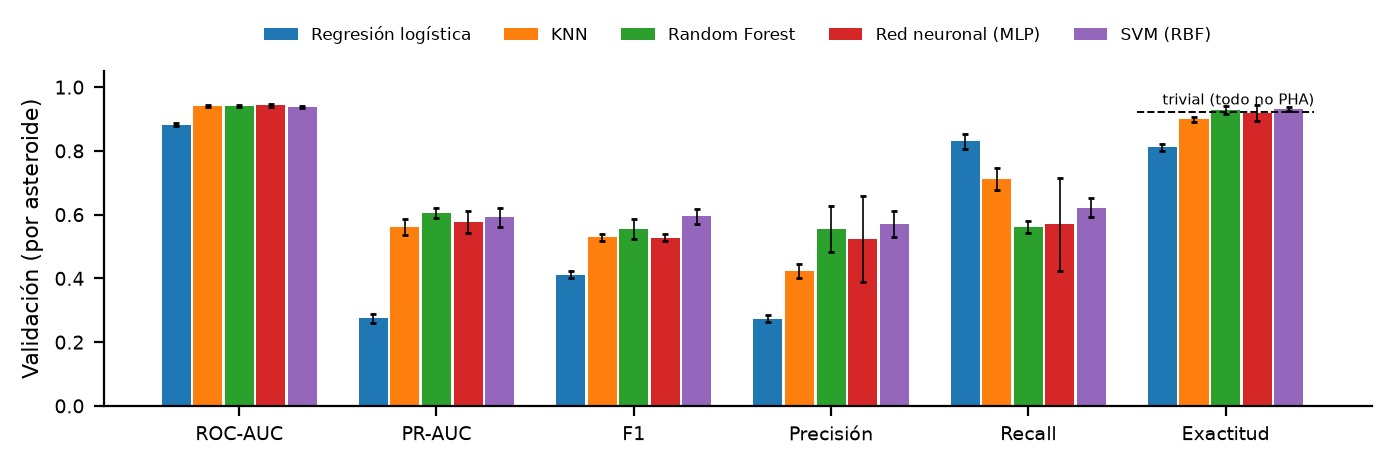

In [17]:
# Figura: métricas de validación por asteroide (con pesos por id), media ± IC 95 % sobre los 5 pliegues
fig, ax = plt.subplots(figsize=(7.0, 2.4))
mets = METRICS_ID
w = 0.8 / len(MODELS)
for i, m in enumerate(MODELS):
    ev = RID[("Con pesos por id", m)]
    vals = np.array([mean_val(ev, mt) for mt in mets])
    err = np.array([ci95([v[mt] for v in ev["val"]]) for mt in mets])
    ax.bar(np.arange(len(mets)) + (i - (len(MODELS) - 1) / 2) * w, vals, w * 0.92, yerr=err, capsize=1.2,
           error_kw=dict(lw=0.6), color=f"C{i}", label=m)
j = mets.index("Accuracy")
ax.hlines(1 - y_ast_dev.mean(), j - 0.45, j + 0.45, color="k", ls="--", lw=0.7)
ax.text(j + 0.45, 1 - y_ast_dev.mean() + 0.025, "trivial (todo no PHA)", ha="right", fontsize=5.5)
ax.set_xticks(range(len(mets))); ax.set_xticklabels([NOMBRES[m] for m in mets])
ax.set_ylabel("Validación (por asteroide)"); ax.set_ylim(0, 1.05)
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.18), fontsize=6)
fig.tight_layout(); fig_id = fig
plt.show()

**Lectura.** (Ver la sección 6 para la discusión con las cifras.) Promediar las probabilidades por asteroide convierte varias observaciones ruidosas del mismo objeto en una sola predicción más estable, y el peso $1/n$ evita que los asteroides con muchas aproximaciones dominen el ajuste. La exactitud se reporta, pero hay que leerla contra el 92 % del clasificador trivial: con el umbral que maximiza $F_1$ los modelos aceptan falsas alarmas a cambio de detectar la mayoría de los PHA, por lo que su exactitud puede quedar por debajo de esa referencia aunque sean mucho más útiles.

## 3.4 Modelo definido: Random Forest por asteroide

Con el criterio fijado de antemano (mayor PR-AUC por asteroide en validación, con pesos $1/n$), el modelo elegido es el **Random Forest**. Su mejor configuración en la malla de la sección 3.3 quedó en el **borde** (profundidad 4, el mínimo de la malla), así que antes de dar el modelo por definido la búsqueda se amplía alrededor de ese punto y se añaden dos decisiones que la malla original no exploraba:

| Hiperparámetro | Valores |
|---|---|
| Profundidad máxima | 2, 3, 4, 5, 6, 8, 12 |
| Mínimo de muestras por hoja | 1, 10, 50, 200 |
| Variables candidatas por división (`max_features`) | 1, 2 (valor por defecto, $\sqrt5$), 3, 5 (equivale a *bagging*) |
| Agregación de las probabilidades de un asteroide | media, mediana, máximo |

La media suaviza predicciones ruidosas; el máximo responde a la idea física de que basta **una** aproximación cercana (distancia de paso $\le$ 0.05 ua, cota superior del MOID) para que el asteroide sea PHA. Se usan los mismos pliegues, los pesos $1/n$ y el mismo criterio (PR-AUC por asteroide en validación). Después se comprueba si 500 árboles mejoran a 150 y se traza la curva de aprendizaje del modelo definido. **La prueba sigue sin usarse.**

In [18]:
GRID_RF = dict(max_depth=[2, 3, 4, 5, 6, 8, 12], min_samples_leaf=[1, 10, 50, 200], max_features=[1, 2, 3, 5])
AGGS = ("mean", "median", "max")
AGG_ES = {"mean": "media", "median": "mediana", "max": "máximo"}
t0 = time.time()
res_rf = grid_search_id("Random Forest", GRID_RF, AGGS)
print(f"Malla ampliada del Random Forest: {len(ParameterGrid(GRID_RF))} configuraciones x {K_FOLDS} pliegues x "
      f"{len(AGGS)} agregaciones ({(time.time()-t0)/60:.1f} min)")
a_rf = (res_rf.groupby(["max_depth", "min_samples_leaf", "max_features", "agg"])
        .agg(PR_AUC=("PR_AUC", "mean"), PR_sd=("PR_AUC", "std"), ROC_AUC=("ROC_AUC", "mean")).reset_index()
        .sort_values(["PR_AUC", "max_depth"], ascending=[False, True], kind="mergesort"))
display(a_rf.head(10).assign(agg=lambda d: d["agg"].map(AGG_ES)).round(4))
top = a_rf.iloc[0]
best_rf = dict(max_depth=int(top.max_depth), min_samples_leaf=int(top.min_samples_leaf), max_features=int(top.max_features))
AGG_RF = top["agg"]
print("Configuración elegida:", best_rf, "| agregación:", AGG_ES[AGG_RF])
LIMITE_NATURAL = {"min_samples_leaf": {1}, "max_features": {1, 5}}      # no se puede ir más allá de estos valores
for h, vals in GRID_RF.items():
    v = best_rf[h]
    borde = v in (min(vals), max(vals))
    nota = "límite natural" if v in LIMITE_NATURAL.get(h, set()) else ("BORDE de la malla" if borde else "interior")
    print(f"  {h} = {v}: {nota}")

# Comparación de agregaciones con la configuración elegida
agg_cmp = a_rf[(a_rf.max_depth == best_rf["max_depth"]) & (a_rf.min_samples_leaf == best_rf["min_samples_leaf"])
               & (a_rf.max_features == best_rf["max_features"])]
display(agg_cmp.assign(agg=agg_cmp["agg"].map(AGG_ES)).round(4))

Malla ampliada del Random Forest: 112 configuraciones x 5 pliegues x 3 agregaciones (7.9 min)


,max_depth,min_samples_leaf,max_features,agg,PR_AUC,PR_sd,ROC_AUC
174,5,50,3,máximo,0.7008,0.0075,0.9528
210,6,10,3,máximo,0.6997,0.0074,0.9529
162,5,10,3,máximo,0.6994,0.0074,0.9527
222,6,50,3,máximo,0.6993,0.0082,0.9529
270,8,50,3,máximo,0.6986,0.0081,0.9533
225,6,50,5,máximo,0.6986,0.0068,0.9532
150,5,1,3,máximo,0.6986,0.0078,0.9527
213,6,10,5,máximo,0.6985,0.0067,0.9533
198,6,1,3,máximo,0.6977,0.0095,0.9528
177,5,50,5,máximo,0.6975,0.0052,0.9534


Configuración elegida: {'max_depth': 5, 'min_samples_leaf': 50, 'max_features': 3} | agregación: máximo
  max_depth = 5: interior
  min_samples_leaf = 50: interior
  max_features = 3: interior


,max_depth,min_samples_leaf,max_features,agg,PR_AUC,PR_sd,ROC_AUC
174,5,50,3,máximo,0.7008,0.0075,0.9528
175,5,50,3,media,0.6128,0.0136,0.9449
176,5,50,3,mediana,0.5147,0.0147,0.9278


In [19]:
def _task_rf_id(p, k, how, frac=1.0):
    a, b = folds[k]
    if frac < 1:
        rng = np.random.RandomState(k); ug = np.unique(gd[a])
        a = a[np.isin(gd[a], rng.choice(ug, max(2, int(frac * len(ug))), replace=False))]
    s, = fit_scores_w("Random Forest", p, Xd[a], yd[a], gd[a], [Xd[b]], k)
    s_id, y_id = por_asteroide(gd[b], s, yd[b], how)
    return average_precision_score(y_id, s_id)

# ¿Más árboles cambian algo? Misma configuración con 150 y 500 árboles
n_tree = {}
for nt in (150, 500):
    out = Parallel(n_jobs=N_JOBS)(delayed(_task_rf_id)({**best_rf, "n_estimators": nt}, k, AGG_RF) for k in range(K_FOLDS))
    n_tree[nt] = (np.mean(out), ci95(out))
    print(f"{nt} árboles: PR-AUC por asteroide en validación = {np.mean(out):.4f} ± {ci95(out):.4f}")
best_rf["n_estimators"] = max(n_tree, key=lambda nt: n_tree[nt][0])
print("Árboles del modelo definido:", best_rf["n_estimators"])

# Curva de aprendizaje del modelo definido (fracción de asteroides de entrenamiento)
fracs_rf = [0.1, 0.25, 0.5, 0.75, 1.0]
jobs = [(f, k) for f in fracs_rf for k in range(K_FOLDS)]
out = Parallel(n_jobs=N_JOBS)(delayed(_task_rf_id)(best_rf, k, AGG_RF, f) for f, k in jobs)
lc_rf = (pd.DataFrame([dict(frac=f, fold=k, PR_AUC=o) for (f, k), o in zip(jobs, out)])
         .groupby("frac").PR_AUC.agg(["mean", "std"]).reset_index())
display(lc_rf.round(4))

150 árboles: PR-AUC por asteroide en validación = 0.7008 ± 0.0093


500 árboles: PR-AUC por asteroide en validación = 0.7007 ± 0.0092
Árboles del modelo definido: 150


,frac,mean,std
0,0.10,0.6319,0.0332
1,0.25,0.6827,0.0152
2,0.50,0.6950,0.0050
3,0.75,0.6970,0.0096
4,1.00,0.7008,0.0075


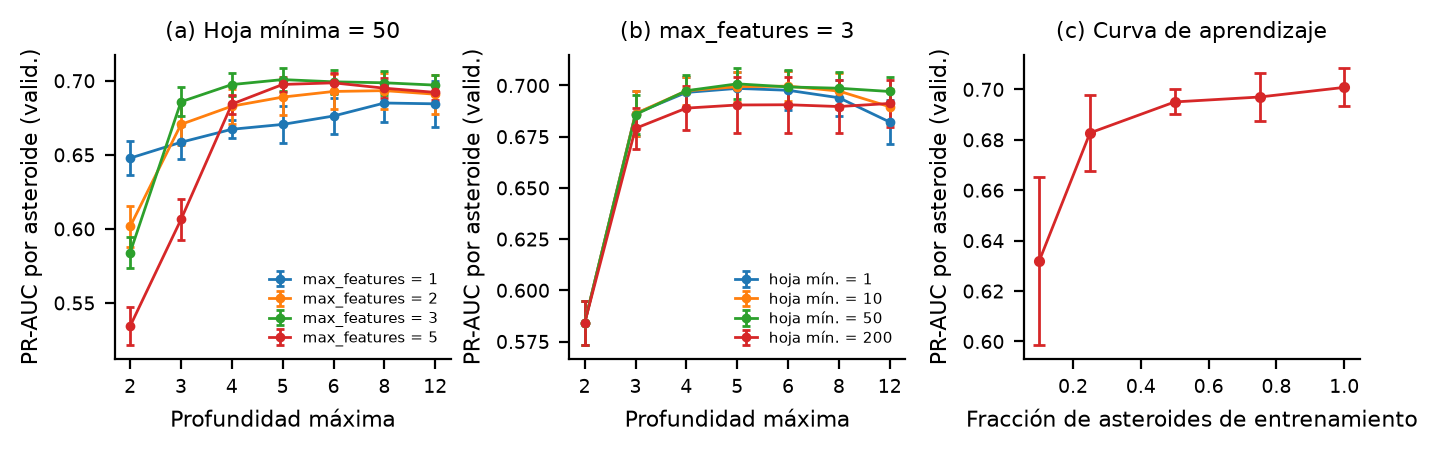

In [20]:
# Figura: malla ampliada del Random Forest (validación por asteroide) y curva de aprendizaje
fig, ax = plt.subplots(1, 3, figsize=(7.0, 2.3))
depths = sorted(GRID_RF["max_depth"])
def _curve(ax_, fixed, hue, fmt):
    g = a_rf[a_rf["agg"] == AGG_RF]
    for kf, vf in fixed.items():
        g = g[g[kf] == vf]
    for h, gh in g.groupby(hue):
        gh = gh.sort_values("max_depth")
        ax_.errorbar(range(len(gh)), gh.PR_AUC, yerr=gh.PR_sd, marker="o", ms=2.5, lw=1, capsize=1.5, label=fmt(h))
    ax_.set_xticks(range(len(depths))); ax_.set_xticklabels(depths)
    ax_.set_xlabel("Profundidad máxima"); ax_.set_ylabel("PR-AUC por asteroide (valid.)")
    ax_.legend(loc="lower right", **LEG)
_curve(ax[0], {"min_samples_leaf": best_rf["min_samples_leaf"]}, "max_features", lambda h: f"max_features = {int(h)}")
ax[0].set_title(f"(a) Hoja mínima = {best_rf['min_samples_leaf']}")
_curve(ax[1], {"max_features": best_rf["max_features"]}, "min_samples_leaf", lambda h: f"hoja mín. = {int(h)}")
ax[1].set_title(f"(b) max_features = {best_rf['max_features']}")
ax[2].errorbar(lc_rf.frac, lc_rf["mean"], yerr=lc_rf["std"], marker="o", ms=3, lw=1, capsize=2, color="C3")
ax[2].set_xlabel("Fracción de asteroides de entrenamiento"); ax[2].set_ylabel("PR-AUC por asteroide (valid.)")
ax[2].set_title("(c) Curva de aprendizaje")
fig.tight_layout(); fig_rf = fig
plt.show()

In [21]:
# Modelo definido frente al Random Forest de la malla original (ambos con pesos 1/n), entrenamiento y validación por asteroide
RF_DEF = eval_id("Random Forest", best_rf, pesos=True, how=AGG_RF)
rows = []
for lab, ev in [("Random Forest, malla de 3.3 (media)", RID[("Con pesos por id", "Random Forest")]),
                (f"Random Forest definido ({AGG_ES[AGG_RF]})", RF_DEF)]:
    row = {"Modelo": lab, "Umbral": round(float(ev["thr"]), 3)}
    for mt in METRICS_ID:
        row[f"{NOMBRES[mt]} entren."] = f"{np.mean([v[mt] for v in ev['train']]):.3f}"
        row[f"{NOMBRES[mt]} valid."] = fmt_val_id(ev, mt)
    rows.append(row)
tab_rf = pd.DataFrame(rows); display(tab_rf.set_index("Modelo").T)
print("Modelo definido:", best_rf, "| agregación:", AGG_ES[AGG_RF], f"| umbral = {RF_DEF['thr']:.3f}")

Modelo,"Random Forest, malla de 3.3 (media)",Random Forest definido (máximo)
Umbral,0.262,0.33
ROC-AUC entren.,0.945,0.956
ROC-AUC valid.,0.941 ± 0.004,0.953 ± 0.003
PR-AUC entren.,0.623,0.713
PR-AUC valid.,0.605 ± 0.016,0.701 ± 0.009
F1 entren.,0.563,0.611
F1 valid.,0.556 ± 0.031,0.602 ± 0.019
Precisión entren.,0.561,0.610
Precisión valid.,0.555 ± 0.071,0.600 ± 0.066
Recall entren.,0.567,0.615


Modelo definido: {'max_depth': 5, 'min_samples_leaf': 50, 'max_features': 3, 'n_estimators': 150} | agregación: máximo | umbral = 0.330


# 4. Reducción de dimensión

Se evalúan los **dos mejores modelos por asteroide** de la sección 3 (PR-AUC de validación con pesos $1/n$): el Random Forest definido en 3.4 y el segundo de la sección 3.3, con sus hiperparámetros ya seleccionados. Todas las métricas son **por asteroide y de validación**; la prueba no se usa.

## 4.1 Análisis individual de variables

Para cada variable (sobre el conjunto de desarrollo) se calculan: la correlación de Spearman con la etiqueta, el AUC univariado y su índice de discriminación ($2|{\rm AUC}-0.5|$), la información mutua con la etiqueta, la máxima correlación con otra variable (redundancia) y el cambio de PR-AUC por asteroide de validación al **eliminar** la variable del Random Forest definido.

In [22]:
TOP2 = ["Random Forest", SECOND_ID]
P_RED = {"Random Forest": best_rf, SECOND_ID: best_id[SECOND_ID]}
HOW_RED = {"Random Forest": AGG_RF, SECOND_ID: "mean"}
print("Modelos para la reducción de dimensión:", TOP2)

rho = [abs(stats.spearmanr(Xd[:, j], yd)[0]) for j in range(5)]
auc_u = [roc_auc_score(yd, Xd[:, j]) for j in range(5)]
auc_u = [max(a_, 1 - a_) for a_ in auc_u]
mi = mutual_info_classif(Xd, yd, random_state=SEED, n_neighbors=5)
cm = np.abs(pd.DataFrame(Xd).corr(method="spearman").to_numpy()); np.fill_diagonal(cm, 0)
max_corr = cm.max(axis=1)

def _task_lofo(name, p, cols, k, how):
    a, b = folds[k]
    s, = fit_scores_w(name, p, Xd[a][:, cols], yd[a], gd[a], [Xd[b][:, cols]], k)
    s_id, y_id = por_asteroide(gd[b], s, yd[b], how)
    return average_precision_score(y_id, s_id)

variants = {"todas": list(range(5))}
variants.update({FEATURES[j]: [c for c in range(5) if c != j] for j in range(5)})
jobs = [(v, k) for v in variants for k in range(K_FOLDS)]
out = Parallel(n_jobs=N_JOBS)(delayed(_task_lofo)("Random Forest", best_rf, variants[v], k, AGG_RF) for v, k in jobs)
lofo = pd.DataFrame([dict(v=v, k=k, pr=o) for (v, k), o in zip(jobs, out)]).groupby("v").pr.mean()
tab_ind = pd.DataFrame({"Variable": FEATURES, "|ρ| Spearman": np.round(rho, 3), "AUC univariado": np.round(auc_u, 3),
                        "Índice discr. (2|AUC−0.5|)": np.round([2 * abs(a_ - 0.5) for a_ in auc_u], 3),
                        "Info. mutua": np.round(mi, 4), "Máx. |ρ| con otra": np.round(max_corr, 3),
                        "Δ PR-AUC por asteroide al eliminar (RF)": [round(lofo[f] - lofo["todas"], 4) for f in FEATURES]})
display(tab_ind)
print(f"PR-AUC por asteroide de validación con todas las variables (RF definido): {lofo['todas']:.4f}")
print("Candidatas a eliminar: variables con máx. |ρ| >= 0.95 (redundantes) o índice de discriminación bajo y Δ PR-AUC ≈ 0.")

Modelos para la reducción de dimensión: ['Random Forest', 'SVM (RBF)']


,Variable,|ρ| Spearman,AUC univariado,Índice discr. (2|AUC−0.5|),Info. mutua,Máx. |ρ| con otra,Δ PR-AUC por asteroide al eliminar (RF)
0,log10 d_min,0.373,0.863,0.726,0.1466,1.000,-0.0001
1,log10 d_max,0.373,0.863,0.726,0.1462,1.000,-0.0001
2,velocidad,0.188,0.683,0.366,0.0216,0.339,-0.0126
3,dist. de paso,0.043,0.542,0.084,0.0061,0.327,-0.3342
4,H,0.373,0.863,0.726,0.1453,1.000,0.0004


PR-AUC por asteroide de validación con todas las variables (RF definido): 0.7008
Candidatas a eliminar: variables con máx. |ρ| >= 0.95 (redundantes) o índice de discriminación bajo y Δ PR-AUC ≈ 0.


### ¿Por qué pesa `miss_distance` si sola discrimina poco?

Su AUC univariado es bajo (0.54), pero eliminarla del modelo reduce mucho la PR-AUC. Una razón física: la distancia de paso en una aproximación **nunca es menor que el MOID** del asteroide. Por tanto, si un objeto con $H\le22$ pasa a menos de 0.05 ua, su MOID cumple $\le 0.05$ ua y es PHA. Se comprueba con el conjunto de desarrollo, por fila y por asteroide (usando la menor distancia de paso entre sus aproximaciones).

In [23]:
AU_KM = 149597870.7
lim = 0.05 * AU_KM                                    # 0.05 ua en km (umbral de MOID de la definición de PHA)
H_, d_, y_ = Xd[:, 4], Xd[:, 3], yd
grupos = {"H <= 22 y dist. <= 0.05 ua": (H_ <= 22) & (d_ <= lim),
          "H <= 22 y dist. > 0.05 ua": (H_ <= 22) & (d_ > lim),
          "H > 22": H_ > 22}
tab_regla = pd.DataFrame([(k, int(m.sum()), int(y_[m].sum()), round(float(y_[m].mean()), 4)) for k, m in grupos.items()],
                         columns=["Grupo de filas", "Filas", "PHA", "Fracción PHA"])
display(tab_regla)
r = grupos["H <= 22 y dist. <= 0.05 ua"]
print(f"Por fila: la regla 'H<=22 y distancia<=0.05 ua' cubre {int(y_[r].sum())} de {int(y_.sum())} filas PHA "
      f"({y_[r].sum()/y_.sum():.1%}) con precisión {y_[r].mean():.3f}")
d_min = pd.Series(d_).groupby(gd).min(); H_ast = pd.Series(H_).groupby(gd).first(); y_ast = pd.Series(y_).groupby(gd).first()
r_ast = (H_ast <= 22) & (d_min <= lim)
print(f"Por asteroide (menor distancia de paso): cubre {int(y_ast[r_ast].sum())} de {int(y_ast.sum())} asteroides PHA "
      f"({y_ast[r_ast].sum()/y_ast.sum():.1%}) con precisión {y_ast[r_ast].mean():.3f}")

,Grupo de filas,Filas,PHA,Fracción PHA
0,H <= 22 y dist. <= 0.05 ua,494,483,0.9777
1,H <= 22 y dist. > 0.05 ua,22878,6517,0.2849
2,H > 22,49296,72,0.0015


Por fila: la regla 'H<=22 y distancia<=0.05 ua' cubre 483 de 7072 filas PHA (6.8%) con precisión 0.978
Por asteroide (menor distancia de paso): cubre 424 de 1739 asteroides PHA (24.4%) con precisión 0.977


## 4.2 Extracción de características lineal: PCA

Se aplica PCA sobre las 5 variables estandarizadas, **ajustado dentro de cada pliegue** (solo con entrenamiento), y se evalúan $k=1,\dots,4$ componentes. Como referencia de **selección** de características se evalúan también las 3 variables independientes del análisis 4.1 ($H$, velocidad y distancia de paso, sin los diámetros). **Criterio para el número de componentes:** el menor $k$ cuya varianza explicada acumulada (en desarrollo) es $\ge 99\,\%$; se contrasta con la PR-AUC por asteroide de validación para cada $k$.

In [24]:
def pca_folds(cols):
    """PCA ajustado solo con el entrenamiento de cada pliegue. Devuelve (Ztr por pliegue, Zva por pliegue, varianza explicada en desarrollo)."""
    tr, va = [], []
    for a, b in folds:
        sc = StandardScaler().fit(Xd[a][:, cols]); pc = PCA().fit(sc.transform(Xd[a][:, cols]))
        tr.append(pc.transform(sc.transform(Xd[a][:, cols]))); va.append(pc.transform(sc.transform(Xd[b][:, cols])))
    evr = PCA().fit(StandardScaler().fit_transform(Xd[:, cols])).explained_variance_ratio_
    return tr, va, evr

def _fit_val_repr(name, p, Ztr, Zva, k):
    a, b = folds[k]
    s, = fit_scores_w(name, p, Ztr, yd[a], gd[a], [Zva], k)
    return s

def eval_repr(name, p, tr_list, va_list, how):
    """Validación por asteroide (5 pliegues) para una representación dada como listas por pliegue."""
    res = Parallel(n_jobs=N_JOBS)(delayed(_fit_val_repr)(name, p, tr_list[k], va_list[k], k) for k in range(K_FOLDS))
    oof = np.zeros(len(yd))
    for k, (a, b) in enumerate(folds):
        oof[b] = res[k]
    s_oof, y_oof = por_asteroide(gd, oof, yd, how)
    thr = best_f1_threshold(y_oof, s_oof)
    va = []
    for k, (a, b) in enumerate(folds):
        s_, y_ = por_asteroide(gd[b], res[k], yd[b], how); va.append(metrics_id(y_, s_, thr))
    return dict(thr=thr, oof=oof, val=va)

t0 = time.time()
PCA_TR, PCA_VA, PCA_EVR = pca_folds([0, 1, 2, 3, 4])
PCA_K = int(np.argmax(np.cumsum(PCA_EVR) >= 0.99) + 1)
print(f"Varianza explicada por componente = {np.round(PCA_EVR, 4)}  -> k (>=99 %) = {PCA_K}")
RED = {}                                     # (representación, dimensiones, modelo) -> evaluación de validación
SEL = [2, 3, 4]
for m in TOP2:
    RED[("Original (5 variables)", 5, m)] = eval_repr(m, P_RED[m], [Xd[a] for a, b in folds], [Xd[b] for a, b in folds], HOW_RED[m])
    RED[("Selección (H, velocidad, distancia)", 3, m)] = eval_repr(m, P_RED[m], [Xd[a][:, SEL] for a, b in folds],
                                                                   [Xd[b][:, SEL] for a, b in folds], HOW_RED[m])
    for k in range(1, 5):
        RED[("PCA", k, m)] = eval_repr(m, P_RED[m], [z[:, :k] for z in PCA_TR], [z[:, :k] for z in PCA_VA], HOW_RED[m])
    print(f"   {m}: listo ({(time.time()-t0)/60:.1f} min)")

Varianza explicada por componente = [0.6598 0.2079 0.1323 0.     0.    ]  -> k (>=99 %) = 3


   Random Forest: listo (0.7 min)


   SVM (RBF): listo (1.9 min)


In [25]:
def red_rows(filtro):
    return pd.DataFrame([{"Entrada": r, "Dim.": k, "Reducción (%)": round(100 * (1 - k / 5)), "Modelo": m,
                          "PR-AUC valid.": fmt_val_id(ev, "PR_AUC"), "ROC-AUC valid.": fmt_val_id(ev, "ROC_AUC"),
                          "F1 valid.": fmt_val_id(ev, "F1")}
                         for (r, k, m), ev in RED.items() if filtro(r)])
tab_pca = red_rows(lambda r: r != "UMAP"); display(tab_pca)

,Entrada,Dim.,Reducción (%),Modelo,PR-AUC valid.,ROC-AUC valid.,F1 valid.
0,Original (5 variables),5,0,Random Forest,0.701 ± 0.009,0.953 ± 0.003,0.602 ± 0.019
1,"Selección (H, velocidad, distancia)",3,40,Random Forest,0.698 ± 0.006,0.953 ± 0.003,0.605 ± 0.015
2,PCA,1,80,Random Forest,0.256 ± 0.009,0.866 ± 0.007,0.368 ± 0.017
3,PCA,2,60,Random Forest,0.407 ± 0.027,0.902 ± 0.004,0.431 ± 0.017
4,PCA,3,40,Random Forest,0.589 ± 0.035,0.946 ± 0.005,0.574 ± 0.014
5,PCA,4,20,Random Forest,0.598 ± 0.024,0.946 ± 0.004,0.571 ± 0.014
6,Original (5 variables),5,0,SVM (RBF),0.591 ± 0.031,0.938 ± 0.004,0.595 ± 0.024
7,"Selección (H, velocidad, distancia)",3,40,SVM (RBF),0.583 ± 0.036,0.934 ± 0.004,0.589 ± 0.019
8,PCA,1,80,SVM (RBF),0.130 ± 0.032,0.695 ± 0.084,0.230 ± 0.055
9,PCA,2,60,SVM (RBF),0.325 ± 0.018,0.862 ± 0.008,0.351 ± 0.011


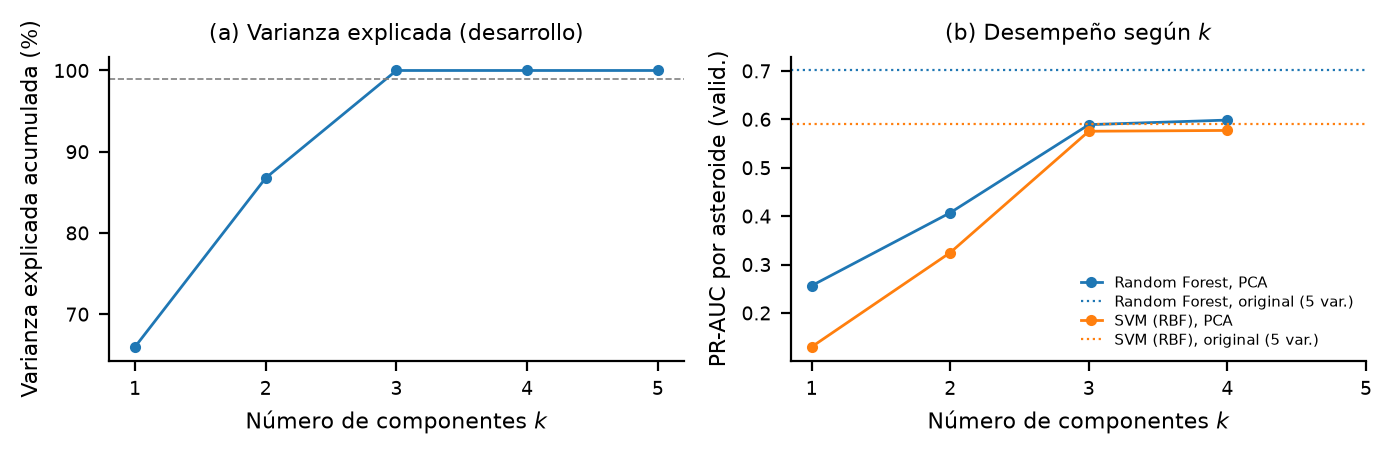

In [26]:
# Figura: PCA
fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.3))
ax[0].plot(range(1, len(PCA_EVR) + 1), np.cumsum(PCA_EVR) * 100, marker="o", ms=3, lw=1, color="C0")
ax[0].axhline(99, color="gray", ls="--", lw=.6); ax[0].set_xlabel("Número de componentes $k$"); ax[0].set_ylabel("Varianza explicada acumulada (%)")
ax[0].set_title("(a) Varianza explicada (desarrollo)")
for i, m in enumerate(TOP2):
    ks = list(range(1, 5))
    ax[1].plot(ks, [mean_val(RED[("PCA", k, m)], "PR_AUC") for k in ks], marker="o", ms=3, lw=1, color=f"C{i}", label=f"{m}, PCA")
    ax[1].axhline(mean_val(RED[("Original (5 variables)", 5, m)], "PR_AUC"), color=f"C{i}", lw=.8, ls=":", label=f"{m}, original (5 var.)")
ax[1].set_xlabel("Número de componentes $k$"); ax[1].set_ylabel("PR-AUC por asteroide (valid.)"); ax[1].set_title("(b) Desempeño según $k$")
ax[1].legend(loc="lower right", **LEG)
for a_ in ax: a_.set_xticks(range(1, 6))
fig.tight_layout(); fig_pca = fig
plt.show()

## 4.3 Extracción de características no lineal: UMAP

**A. Evaluación.** UMAP (`n_neighbors=15`, `min_dist=0.1`, distancia euclídea, **sin usar la etiqueta**) se ajusta **dentro de cada pliegue solo con el entrenamiento**, y la validación se proyecta con `transform`. Se prueban $n_{\rm comp}\in\{2,3,4\}$ sobre las 5 variables estandarizadas, con métricas por asteroide en validación. **Criterio:** el $n_{\rm comp}$ con mayor PR-AUC de validación promedio entre los dos modelos. La proyección bidimensional de la figura se ajusta solo con el conjunto de desarrollo.

In [27]:
def umap_fold(nc, k):
    a, b = folds[k]
    sc = StandardScaler().fit(Xd[a]); um = umap.UMAP(n_components=nc, n_neighbors=15, min_dist=0.1, random_state=SEED)
    return um.fit_transform(sc.transform(Xd[a])), um.transform(sc.transform(Xd[b]))

t0 = time.time()
NCS = [2, 3, 4]
for nc in NCS:
    emb = Parallel(n_jobs=N_JOBS)(delayed(umap_fold)(nc, k) for k in range(K_FOLDS))
    for m in TOP2:
        RED[("UMAP", nc, m)] = eval_repr(m, P_RED[m], [e[0] for e in emb], [e[1] for e in emb], HOW_RED[m])
    print(f"UMAP n_comp={nc}: listo ({(time.time()-t0)/60:.1f} min)")
# Proyección 2D ajustada solo con el desarrollo, para la figura
sc_u = StandardScaler().fit(Xd)
UMAP_EMB = (umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(sc_u.transform(Xd)), yd)

UMAP n_comp=2: listo (3.4 min)


UMAP n_comp=3: listo (5.3 min)


UMAP n_comp=4: listo (7.2 min)


,Entrada,Dim.,Reducción (%),Modelo,PR-AUC valid.,ROC-AUC valid.,F1 valid.
0,UMAP,2,60,Random Forest,0.438 ± 0.029,0.915 ± 0.007,0.448 ± 0.036
1,UMAP,2,60,SVM (RBF),0.246 ± 0.066,0.838 ± 0.040,0.350 ± 0.046
2,UMAP,3,40,Random Forest,0.535 ± 0.026,0.938 ± 0.002,0.538 ± 0.010
3,UMAP,3,40,SVM (RBF),0.503 ± 0.035,0.932 ± 0.003,0.550 ± 0.018
4,UMAP,4,20,Random Forest,0.544 ± 0.038,0.942 ± 0.005,0.545 ± 0.018
5,UMAP,4,20,SVM (RBF),0.516 ± 0.021,0.934 ± 0.003,0.557 ± 0.010


PR-AUC de validación promedio por n_comp: {2: np.float64(0.3422), 3: np.float64(0.519), 4: np.float64(0.5298)} -> elegido: 4


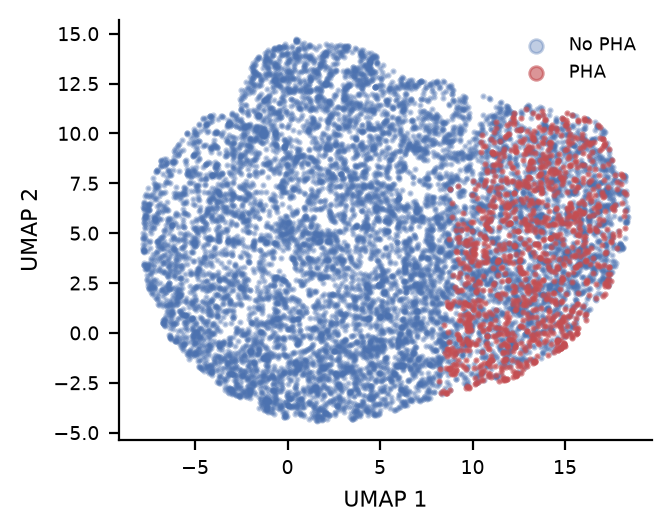

In [28]:
tab_umap = red_rows(lambda r: r == "UMAP"); display(tab_umap)
mean_val_nc = {nc: np.mean([mean_val(RED[("UMAP", nc, m)], "PR_AUC") for m in TOP2]) for nc in NCS}
NC_BEST = max(mean_val_nc, key=mean_val_nc.get)
print("PR-AUC de validación promedio por n_comp:", {k: round(v, 4) for k, v in mean_val_nc.items()}, "-> elegido:", NC_BEST)

# Figura: proyección UMAP 2D
Z2, y2 = UMAP_EMB
sel = np.random.RandomState(0).choice(len(y2), min(12000, len(y2)), replace=False)
fig, ax = plt.subplots(figsize=(3.4, 2.7))
ax.scatter(Z2[sel][y2[sel] == 0, 0], Z2[sel][y2[sel] == 0, 1], s=1.5, c="#4C72B0", alpha=.35, label="No PHA", rasterized=True)
ax.scatter(Z2[sel][y2[sel] == 1, 0], Z2[sel][y2[sel] == 1, 1], s=1.5, c="#C44E52", alpha=.6, label="PHA", rasterized=True)
ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2"); ax.legend(frameon=False, markerscale=4, loc="best")
fig.tight_layout(); fig_umap = fig
plt.show()

## 4.4 Representación del modelo definido

Regla fijada antes de usar la prueba: entre las representaciones evaluadas con el Random Forest (original, selección de 3 variables, PCA y UMAP), se toma la de mayor PR-AUC media por asteroide en validación; si otra con **menos dimensiones** queda dentro de su IC 95 %, se prefiere la de menos dimensiones (igual de buena y más simple).

In [29]:
cand = {(r, k): ev for (r, k, m), ev in RED.items() if m == "Random Forest"}
mu = {key: mean_val(ev, "PR_AUC") for key, ev in cand.items()}
best_key = max(mu, key=mu.get)
lo = mu[best_key] - ci95([v["PR_AUC"] for v in cand[best_key]["val"]])
eleg = [key for key in mu if mu[key] >= lo]
REPR = min(eleg, key=lambda key: (key[1], -mu[key]))
tab_repr = pd.DataFrame([{"Representación": r, "Dim.": k, "PR-AUC valid.": fmt_val_id(cand[(r, k)], "PR_AUC"),
                          "Dentro del IC 95 % del mejor": "sí" if (r, k) in eleg else "no"}
                         for (r, k) in sorted(cand, key=lambda x: -mu[x])])
display(tab_repr)
print("Representación del modelo definido:", REPR)

,Representación,Dim.,PR-AUC valid.,Dentro del IC 95 % del mejor
0,Original (5 variables),5,0.701 ± 0.009,sí
1,"Selección (H, velocidad, distancia)",3,0.698 ± 0.006,sí
2,PCA,4,0.598 ± 0.024,no
3,PCA,3,0.589 ± 0.035,no
4,UMAP,4,0.544 ± 0.038,no
5,UMAP,3,0.535 ± 0.026,no
6,UMAP,2,0.438 ± 0.029,no
7,PCA,2,0.407 ± 0.027,no
8,PCA,1,0.256 ± 0.009,no


Representación del modelo definido: ('Selección (H, velocidad, distancia)', 3)


# 5. Evaluación final en prueba

Hasta aquí todas las decisiones se tomaron solo con el conjunto de desarrollo: el modelo (Random Forest), sus hiperparámetros (malla ampliada, 3.4), los pesos $1/n$, la agregación por asteroide, la representación de entrada (4.4) y el umbral, que maximiza $F_1$ sobre las predicciones fuera de muestra por asteroide. Con el modelo así **definido**, se reentrena con todo el desarrollo y se evalúa **una sola vez** en la prueba (asteroides nunca vistos). Como referencia, no como candidatos, se reportan el clasificador constante y la regresión logística con solo $H$, también ajustada con el desarrollo y con su umbral de validación.

In [30]:
r_name, r_dim = REPR
def repr_transform(r, k):
    """Transformación de la representación elegida, ajustada solo con el desarrollo."""
    if r.startswith("Original"):
        return lambda Z: Z
    if r.startswith("Selección"):
        return lambda Z: Z[:, SEL]
    sc = StandardScaler().fit(Xd)
    if r == "PCA":
        pc = PCA().fit(sc.transform(Xd))
        return lambda Z: pc.transform(sc.transform(Z))[:, :k]
    um = umap.UMAP(n_components=k, n_neighbors=15, min_dist=0.1, random_state=SEED).fit(sc.transform(Xd))
    return lambda Z: um.transform(sc.transform(Z))

T = repr_transform(r_name, r_dim)
ev_def = RED[(r_name, r_dim, "Random Forest")]
THR_DEF = float(ev_def["thr"])
print("MODELO DEFINIDO:", "Random Forest", best_rf, "| pesos 1/n | agregación:", AGG_ES[AGG_RF],
      "| entrada:", REPR, f"| umbral = {THR_DEF:.3f}")

# ------------------------- Única evaluación en el conjunto de prueba -------------------------
s_test_rows, = fit_scores_w("Random Forest", best_rf, T(Xd), yd, gd, [T(Xt)], seed=99)
s_test_id, y_test_id = por_asteroide(gt, s_test_rows, yt, AGG_RF)
# Referencias
s_H_rows, = fit_scores_w("Regresión logística", dict(C=1, class_weight="ninguno"), Xd[:, [4]], yd, gd, [Xt[:, [4]]], seed=99)
s_H_id, _ = por_asteroide(gt, s_H_rows, yt, "mean")
FINAL = {"Random Forest definido": (s_test_id, THR_DEF),
         "Solo H (reg. logística)": (s_H_id, float(RID[("Con pesos por id", "Solo H (reg. logística)")]["thr"])),
         "Constante (todo PHA)": (np.zeros(len(y_test_id)), 0.0)}
boot_f = boot_id(FINAL, y_test_id)
M_TEST = {lab: metrics_id(y_test_id, s, thr) for lab, (s, thr) in FINAL.items()}
tab_test = pd.DataFrame([{"Modelo": lab, **{NOMBRES[mt]: f"{M_TEST[lab][mt]:.3f} [{boot_f[lab][mt][0]:.3f}, {boot_f[lab][mt][1]:.3f}]"
                                            for mt in METRICS_ID}} for lab in FINAL])
print(f"Prueba: {len(y_test_id):,} asteroides ({int(y_test_id.sum())} PHA, {y_test_id.mean():.3f}); "
      f"exactitud del trivial (todo no PHA) = {1 - y_test_id.mean():.3f}")
display(tab_test)

# Validación frente a prueba del modelo definido
comp = pd.DataFrame({"Validación (media ± IC95)": {NOMBRES[mt]: fmt_val_id(ev_def, mt) for mt in METRICS_ID},
                     "Prueba [IC95]": {NOMBRES[mt]: tab_test.set_index("Modelo").loc["Random Forest definido", NOMBRES[mt]] for mt in METRICS_ID}})
display(comp)

# Matriz de confusión por asteroide al umbral elegido
pred = s_test_id >= THR_DEF
tab_cm = pd.DataFrame([[int(((y_test_id == 0) & ~pred).sum()), int(((y_test_id == 0) & pred).sum())],
                       [int(((y_test_id == 1) & ~pred).sum()), int(((y_test_id == 1) & pred).sum())]],
                      index=["Real: no PHA", "Real: PHA"], columns=["Predicho: no PHA", "Predicho: PHA"])
display(tab_cm)

# Las mismas predicciones, por fila (aproximación), solo métricas que no dependen del umbral
print(f"Por fila (aproximación): ROC-AUC = {roc_auc_score(yt, s_test_rows):.3f} | PR-AUC = {average_precision_score(yt, s_test_rows):.3f}")
# Dentro de H <= 22, por asteroide
H_test_id = pd.Series(Xt[:, 4]).groupby(gt).first().to_numpy()
mk = H_test_id <= 22
print(f"Asteroides de prueba con H <= 22: {mk.sum()} (PHA {y_test_id[mk].mean():.3f}); RF definido ROC-AUC = "
      f"{roc_auc_score(y_test_id[mk], s_test_id[mk]):.3f}, PR-AUC = {average_precision_score(y_test_id[mk], s_test_id[mk]):.3f}; "
      f"solo H ROC-AUC = {roc_auc_score(y_test_id[mk], -H_test_id[mk]):.3f}")

MODELO DEFINIDO: Random Forest {'max_depth': 5, 'min_samples_leaf': 50, 'max_features': 3, 'n_estimators': 150} | pesos 1/n | agregación: máximo | entrada: ('Selección (H, velocidad, distancia)', 3) | umbral = 0.333


Prueba: 5,485 asteroides (434 PHA, 0.079); exactitud del trivial (todo no PHA) = 0.921


,Modelo,ROC-AUC,PR-AUC,F1,Precisión,Recall,Exactitud
0,Random Forest definido,"0.952 [0.945, 0.958]","0.669 [0.632, 0.707]","0.591 [0.553, 0.625]","0.528 [0.489, 0.568]","0.671 [0.624, 0.711]","0.927 [0.920, 0.934]"
1,Solo H (reg. logística),"0.859 [0.848, 0.869]","0.240 [0.211, 0.271]","0.387 [0.360, 0.409]","0.240 [0.220, 0.257]","0.991 [0.980, 0.998]","0.751 [0.739, 0.763]"
2,Constante (todo PHA),"0.500 [0.500, 0.500]","0.079 [0.072, 0.086]","0.147 [0.135, 0.158]","0.079 [0.072, 0.086]","1.000 [1.000, 1.000]","0.079 [0.072, 0.086]"


,Validación (media ± IC95),Prueba [IC95]
ROC-AUC,0.953 ± 0.003,"0.952 [0.945, 0.958]"
PR-AUC,0.698 ± 0.006,"0.669 [0.632, 0.707]"
F1,0.605 ± 0.015,"0.591 [0.553, 0.625]"
Precisión,0.549 ± 0.039,"0.528 [0.489, 0.568]"
Recall,0.676 ± 0.025,"0.671 [0.624, 0.711]"
Exactitud,0.930 ± 0.007,"0.927 [0.920, 0.934]"


,Predicho: no PHA,Predicho: PHA
Real: no PHA,4791,260
Real: PHA,143,291


Por fila (aproximación): ROC-AUC = 0.906 | PR-AUC = 0.468
Asteroides de prueba con H <= 22: 1791 (PHA 0.240); RF definido ROC-AUC = 0.828, PR-AUC = 0.673; solo H ROC-AUC = 0.481


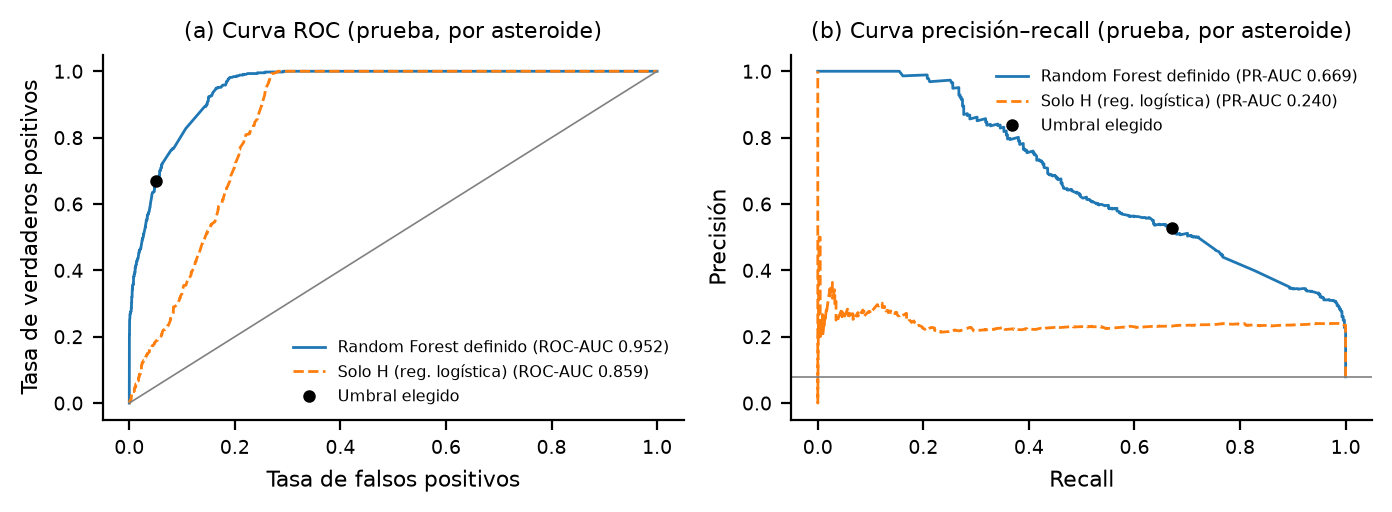

Tiempo total de ejecución: 30.2 min


In [31]:
# Figura: curvas ROC y PR del modelo definido en la prueba (por asteroide)
fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.6))
for lab, ls in [("Random Forest definido", "-"), ("Solo H (reg. logística)", "--")]:
    s = FINAL[lab][0]
    fpr, tpr, _ = roc_curve(y_test_id, s); ax[0].plot(fpr, tpr, lw=1, ls=ls, label=f"{lab} (ROC-AUC {M_TEST[lab]['ROC_AUC']:.3f})")
    p_, r_, _ = precision_recall_curve(y_test_id, s); ax[1].plot(r_, p_, lw=1, ls=ls, label=f"{lab} (PR-AUC {M_TEST[lab]['PR_AUC']:.3f})")
m_ = M_TEST["Random Forest definido"]
fpr_op = float(((s_test_id >= THR_DEF) & (y_test_id == 0)).sum() / (y_test_id == 0).sum())
ax[0].plot(fpr_op, m_["Recall"], "o", color="k", ms=3.5, label="Umbral elegido")
ax[1].plot(m_["Recall"], m_["Precision"], "o", color="k", ms=3.5, label="Umbral elegido")
ax[0].plot([0, 1], [0, 1], color="gray", lw=.6); ax[1].axhline(y_test_id.mean(), color="gray", lw=.6)
ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos"); ax[0].set_title("(a) Curva ROC (prueba, por asteroide)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precisión"); ax[1].set_title("(b) Curva precisión–recall (prueba, por asteroide)")
for a_ in ax: a_.legend(frameon=False, loc="lower right" if a_ is ax[0] else "upper right", fontsize=5.8)
fig.tight_layout(); fig_final = fig
plt.show()
print(f"Tiempo total de ejecución: {(time.time()-t_start)/60:.1f} min")

# 6. Discusión y conclusiones

**Lectura de los resultados.** Todas las comparaciones se hicieron en validación; la prueba se usó una sola vez, con el modelo definido (sección 5).

- **Por fila (3.2).** KNN, Random Forest y red neuronal empatan en validación (PR-AUC 0.503 a 0.510; ROC-AUC 0.910 a 0.911; $F_1\approx0.48$). La regresión logística (0.302) y el SVM (0.465) quedan por debajo. Frente a usar solo $H$ (PR-AUC 0.275) la mejora es clara en PR-AUC, pero pequeña en $F_1$ (0.461 frente a 0.48).
- **Por asteroide (3.3).** Evaluar al asteroide, que es la unidad que define la etiqueta, sube la PR-AUC de validación de los modelos no lineales a 0.55–0.61. Los pesos $1/n$ mejoran la PR-AUC de validación en los cinco modelos, aunque poco (0.008 a 0.016). Con el criterio fijado de antemano (PR-AUC por asteroide en validación) el elegido es el **Random Forest** (0.605), seguido del SVM (0.591).
- **Modelo definido (3.4).** La malla original dejaba al Random Forest en el borde (profundidad 4). La malla ampliada (112 configuraciones) lo ubica en el interior: profundidad 5, hoja mínima 50 y 3 variables por división. La decisión que más aporta es **cómo se agregan** las probabilidades de un asteroide: el **máximo** (PR-AUC 0.701) supera a la media (0.613) y a la mediana (0.515), porque basta una aproximación cercana para que el asteroide sea PHA. Con 500 árboles el resultado no cambia (0.7007 frente a 0.7008), y la curva de aprendizaje se estanca (de 75 % a 100 % de los datos, +0.004).
- **`miss_distance`.** Sola discrimina poco (AUC 0.54), pero eliminarla del Random Forest baja la PR-AUC por asteroide en 0.334. Si un asteroide con $H\le22$ pasa alguna vez a menos de 0.05 ua es PHA casi seguro (97.7 %), y por asteroide esa regla cubre el 24.4 % de los PHA (por fila, solo el 6.8 %).
- **Reducción de dimensión (4).** Las 5 variables tienen solo 3 dimensiones independientes. Quedarse con $H$, velocidad y distancia (selección, 40 % menos variables) conserva el desempeño del Random Forest (0.698 frente a 0.701) y es la representación elegida. PCA con $k=3$ cumple el criterio de varianza, pero le quita 0.11 de PR-AUC al Random Forest (0.589): al rotar los ejes mezcla $H$ con la distancia y rompe los cortes paralelos a los ejes que los árboles aprovechan ($H\le22$, distancia $\le$ 0.05 ua). En el SVM la pérdida es pequeña (0.575 frente a 0.591). UMAP no mejora (mejor: 4 componentes, 0.544 en el Random Forest).
- **Prueba (5).** El Random Forest definido alcanza, por asteroide, ROC-AUC 0.952, PR-AUC 0.669, $F_1$ 0.591, precisión 0.528, recall 0.671 y exactitud 0.927 (trivial: 0.921), dentro o cerca de los intervalos de validación: no hay señales de sobreajuste a la validación. Detecta 291 de los 434 PHA de prueba con 260 falsas alarmas entre 5 051 no PHA. Frente a usar solo $H$ (PR-AUC 0.240) la mejora es grande.
- **Techo.** La etiqueta depende del MOID, ausente en la base. Dentro de $H\le22$, donde la clase es incierta, el modelo alcanza un ROC-AUC de 0.83 en prueba, mientras que $H$ sola no tiene señal (0.48).
- **Unidades.** Validadas contra aproximaciones publicadas por la NASA (`entregable1.ipynb`, sección 1.B.3): velocidad en km/h y distancia de paso en km desde el centro de la Tierra. Cambiar la unidad de la velocidad no altera ningún resultado.